In [1]:
import numpy as np
import pandas as pd
import h5py
import os
import sys

import matplotlib.pyplot as plt

import astropy.units as u
from astropy.coordinates import SkyCoord
from astropy.io import fits, ascii

from scipy import stats
from scipy.stats import gaussian_kde

In [2]:
from astropy.cosmology import FlatLambdaCDM 
from astropy.cosmology import z_at_value
cosmo = FlatLambdaCDM(H0 = 70, Om0 = 0.3)

In [3]:
"""
plot_style.py
-------------
Master matplotlib/plotly style loader.
Usage:
    from plot_style import *
    from plot_style import get_n_colors, MidFactor
"""

import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.ticker import FuncFormatter, ScalarFormatter, LogLocator
from matplotlib.colors import to_rgba
from matplotlib.gridspec import GridSpec
import matplotlib.patheffects as path_effects
import plotly.graph_objects as go
from matplotlib.lines import Line2D
import matplotlib.patches as Patches
from matplotlib.legend_handler import HandlerTuple
import matplotlib.patheffects as pe
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# ── RC Params ─────────────────────────────────────────────────────────────────
params = {
        # Font
        "font.family":          "serif",
        "font.size":            24,
        "text.usetex":          True,

        # Tick labels
        "xtick.labelsize":      20,
        "ytick.labelsize":      20,

        # Tick direction & size
        "xtick.direction":      "in",
        "ytick.direction":      "in",
        "xtick.major.size":     7,
        "ytick.major.size":     7,
        "xtick.minor.size":     3.5,
        "ytick.minor.size":     3.5,
        "xtick.minor.visible":  False,
        "ytick.minor.visible":  False,

        # Tick padding & axes
        "xtick.major.pad":      7,
        "axes.linewidth":       2.0,

        # tight layout
        "figure.constrained_layout.use": True
    }

plt.rcParams.update(params)


In [4]:
# ── Helpers ───────────────────────────────────────────────────────────────────

# Source - https://stackoverflow.com/a/49601444
# Posted by Ian Hincks, modified by community. See post 'Timeline' for change history
# Retrieved 2026-07-08, License - CC BY-SA 4.0

def lighten_color(color, amount=0.5):
    """
    Lightens the given color by multiplying (1-luminosity) by the given amount.
    Input can be matplotlib color string, hex string, or RGB tuple.

    Examples:
    >> lighten_color('g', 0.3)
    >> lighten_color('#F034A3', 0.6)
    >> lighten_color((.3,.55,.1), 0.5)
    """
    import matplotlib.colors as mc
    import colorsys
    try:
        c = mc.cnames[color]
    except:
        c = color
    c = colorsys.rgb_to_hls(*mc.to_rgb(c))
    return colorsys.hls_to_rgb(c[0], 1 - amount * (1 - c[1]), c[2])

def get_n_colors(n, cmap_name="viridis"):
    """Sample n evenly-spaced colours from a matplotlib colormap."""
    cmap = plt.get_cmap(cmap_name)
    return [cmap(i / max(n - 1, 1)) for i in range(n)]


def MidFactor(n):
    """Return the middle divisor of n (useful for subplot grid layout)."""
    divisors = [i for i in range(1, n + 1) if n % i == 0]
    return divisors[len(divisors) // 2]

# Arrow plot
import matplotlib.path as mpath
def up_arrow_marker():
    Path = mpath.Path
    verts = [
        (0.0, 0.0),        
        (-0.03, 0.0),      
        (-0.28, -0.27),     
        (-0.21, -0.35),    
        (-0.06, -0.2), 
        (-0.06, -1.0),
        (0.06, -1.0),
        (0.06, -0.2), 
        (0.21, -0.35),
        (0.28, -0.27),
        (0.03, 0.0),
        (0.0, 0.0)
    ]
    codes = [Path.MOVETO] + [Path.LINETO]*10 + [Path.CLOSEPOLY]
    return Path(verts, codes)

def down_arrow_marker():
    Path = mpath.Path
    verts = [
        (0.0, 0.0),        # Tip
        (-0.3, 0.3),       # Left of arrowhead
        (-0.05, 0.3),      # Left shaft edge
        (-0.05, 1.0),      # Shaft top left
        (0.05, 1.0),       # Shaft top right
        (0.05, 0.3),       # Right shaft edge
        (0.3, 0.3),        # Right of arrowhead
        (0.0, 0.0),        # Close shape at tip
    ]
    codes = [mpath.Path.MOVETO] + [mpath.Path.LINETO]*6 + [mpath.Path.CLOSEPOLY]

    verts = [
        (0.0, 0.0),        
        (-0.03, 0.0),      
        (-0.28, 0.27),     
        (-0.21, 0.35),    
        (-0.06, 0.2), 
        (-0.06, 1.0),
        (0.06, 1.0),
        (0.06, 0.2), 
        (0.21, 0.35),
        (0.28, 0.27),
        (0.03, 0.0),
        (0.0, 0.0)
    ]
    codes = [Path.MOVETO] + [Path.LINETO]*10 + [Path.CLOSEPOLY]
    
    return Path(verts, codes)

up_arrow_marker = up_arrow_marker()
down_arrow_marker = down_arrow_marker()

grid_alpha = 0.1
grid_color = 'grey'
grid_ls = "-"

# Load in things

In [40]:
h5file = "/Users/jordan/Documents/Epochs/data/analysis_data.h5"
filters_info = pd.read_csv("/Users/jordan/Documents/Epochs/data/throughputs/wavelengths.txt", delimiter=" ")

In [ ]:
# number counts 
smiles_number_counts = pd.read_hdf(h5file, "number_counts/smiles")
midis_number_counts = pd.read_hdf(h5file, "number_counts/midis")

smiles_frame_stats = pd.read_hdf(h5file, "frame_stats/smiles")
midis_frame_stats = pd.read_hdf(h5file, "frame_stats/midis")


prospect_stellar = pd.read_hdf(h5file, "ProSpect/Stellar")
prospect_stellarAGN = pd.read_hdf(h5file, "ProSpect/StellarAGN")
prospect_robust = pd.read_hdf(h5file, "ProSpect/Robust")
prospect_robustDIC = pd.read_hdf(h5file, "ProSpect/RobustDIC")


photoz = pd.read_hdf(h5file, "photoz/photoz")

SMBH_results = pd.read_hdf(h5file, "SMBH/SMBH")

In [57]:
"""Get redshift sample"""

# lbt_bins = np.arange(8.0, 13.5, 0.5)
lbt_bins = np.append(np.arange(8.0, 13.0, 0.5), [13])
zbins = z_at_value(cosmo.lookback_time, lbt_bins*u.Gyr).value
# zbins = np.append(z_at_value(cosmo.lookback_time, lbt_bins*u.Gyr).value, [7,9,11])
zmids = zbins[:-1] + np.diff(zbins)/2.0

sample_idx = (prospect_robust['zQ50'] >= zbins[0]) & (prospect_robust['zQ50'] < zbins[-1])
quenched_idx = prospect_robust["SFR10Q50"][sample_idx]/prospect_robust["StellarMassQ50"][sample_idx] <= 0.2/(1e9*cosmo.age(prospect_robust["zQ50"][sample_idx]).value) # probably just use this for upper limits on the SFR10 plots 

prospect_sample = prospect_robust[sample_idx]
SMBH_results_sample = SMBH_results[sample_idx]

sampleDIC_idx = (prospect_robustDIC['zQ50'] >= zbins[0]) & (prospect_robustDIC['zQ50'] < zbins[-1])
prospect_sampleDIC = prospect_robustDIC[sample_idx]

starforming_sample = prospect_robust[sample_idx][~quenched_idx] 
quenched_sample = prospect_robust[sample_idx][quenched_idx] # for upper limits
minimum_SFR10_vals = quenched_sample["StellarMassQ50"] * 0.2/(1e9*cosmo.age(quenched_sample["zQ50"]).value)

# constants 
LAGN2BHAR = ( 3.154e7 * 1e-7 * (0.1 * 3e8**2)**-1 / 2e30)

# Number counts

In [19]:
stone25 = pd.read_csv(
    os.path.expanduser("~/Documents/Epochs/data/literature/number_counts/stone25.csv")
)

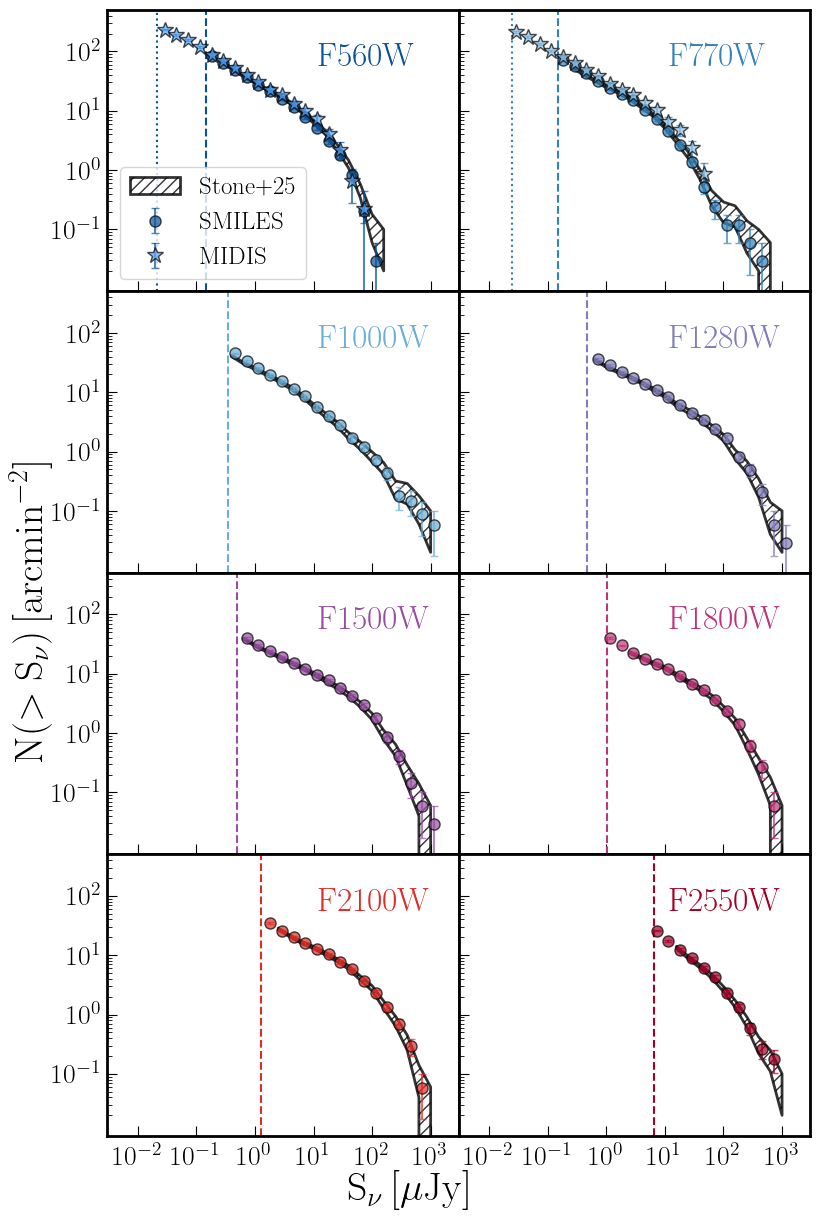

In [20]:
MIRI_keys = ["F560W", "F770W", "F1000W", "F1280W", "F1500W", "F1800W", "F2100W", "F2550W"]
cols = [
  "#2166AC",  # deep blue
  "#4393C3",  # mid blue
  "#92C5DE",  # light blue
  "#EDF176",  # pale yellow-orange
  "#F4A736",  # yellow-orange
  "#E8601C",  # orange
  "#D6301F",  # red-orange
  "#A50026"   # deep red
]
cols = ("#08519C", "#3182BD", "#6BAED6", "#807DBA",
          "#984EA3", "#C0357A", "#DE2D26", "#A50026")

fig, ax = plt.subplots(ncols=2, nrows = 4, sharex = True, sharey = True, figsize = (8,12))
ax = ax.flatten()

fig.get_layout_engine().set(h_pad=0, w_pad=0, hspace=0, wspace=0)

for i, axx in enumerate(ax):
    axx.errorbar(
        smiles_number_counts["uJy_mids"],
        smiles_number_counts[f"{MIRI_keys[i]}_cumul"],
        yerr = smiles_number_counts[f"{MIRI_keys[i]}_cumulerr"],
        capsize = 3,
        fmt = "o",
        markersize = 8,
        markeredgecolor = "black",
        markerfacecolor = cols[i],
        ecolor = cols[i],
        alpha = 0.7, 
        label = "SMILES"
    )
    axx.axvline(
        smiles_frame_stats[f"{MIRI_keys[i]}_5sigma_depth_32asec"].values/1e-6,
        color = cols[i],
        ls = "--"
    )
    if i < 2:
        axx.errorbar(
            midis_number_counts["uJy_mids"],
            midis_number_counts[f"{MIRI_keys[i]}_cumul"],
            yerr = midis_number_counts[f"{MIRI_keys[i]}_cumulerr"],
            capsize = 3,
            fmt = "*",
            markersize = 12,
            markerfacecolor = lighten_color(cols[i], amount= 0.5) ,
            markeredgecolor = "black",
            ecolor = cols[i],
            alpha = 0.7,
            label = "MIDIS"
        )
        axx.axvline(
            midis_frame_stats[f"{MIRI_keys[i]}_5sigma_depth_32asec"].values/1e-6,
            color = cols[i],
            ls = ":"
        )

    if i == 1:
        axx.fill_between(
        # -2.5*np.log10(stone25["Flux_uJy"])+23.9,
        stone25["Flux_uJy"],
        stone25[f"{MIRI_keys[i]}_SMILES"] - stone25[f"{MIRI_keys[i]}_SMILES_err"],
        stone25[f"{MIRI_keys[i]}_SMILES"] + stone25[f"{MIRI_keys[i]}_SMILES_err"],
        facecolor = "none",
        hatch = "///",
        edgecolor = "black",
        alpha = 0.8,
        lw = 2
    )
    else:
        axx.fill_between(
            # -2.5*np.log10(stone25["Flux_uJy"])+23.9,
            stone25["Flux_uJy"],
            stone25[f"{MIRI_keys[i]}"] - stone25[f"{MIRI_keys[i]}_err"],
            stone25[f"{MIRI_keys[i]}"] + stone25[f"{MIRI_keys[i]}_err"],
            facecolor = "none",
            hatch = "///",
            edgecolor = "black",
            alpha = 0.8,
            lw = 2,
            label = "Stone+25"
        )
    axx.text(
        0.6,
        0.8,
        MIRI_keys[i],
        transform = axx.transAxes,
        color = cols[i]
        # path_effects = [pe.Stroke(linewidth=2, foreground='black'), pe.Normal()]
    )

ax[0].legend(
    frameon = True,
    fontsize = 18,
    loc = "lower left"
)
ax[0].set_xscale("log")
ax[0].set_yscale("log")

# ax[0].set_xlim([29, 15])
ax[0].set_xlim([3e-3, 3e3])
ax[0].set_ylim([9e-3, 5e2])

# ax[0].set_xticks([28, 24, 20, 16])
ax[0].set_xticks([1e-2, 1e-1, 1e0, 1e1, 1e2, 1e3])
ax[0].set_yticks([1e-1, 1e0, 1e1, 1e2])

fig.supxlabel(r"$\mathrm{S_{\nu} \, [\mu Jy}]$")
fig.supylabel(r"$\mathrm{N(>S_{\nu}) \, [arcmin^{-2}]}$")

plt.savefig(
    "/Users/jordan/Documents/Epochs/plots/number_counts.pdf", 
    bbox_inches="tight", 
    dpi = 240
)


# Compare EAZY specz and photoz

In [103]:
def compute_sigmaNMAD(zspec, zphot, zphot_lim=0):
    zspec = np.array(zspec)
    zphot = np.array(zphot)
    
    idx = (zphot > zphot_lim) & (~np.isnan(zphot))
    deltaz = zphot[idx] - zspec[idx]
    
    sigmaNMAD = 1.48 * np.median(np.abs((deltaz - np.median(deltaz)) / (1 + zspec[idx])))
    return sigmaNMAD


def compute_outliers(zspec, zphot, thresh=0.15, zphot_lim=-2):
    zspec = np.array(zspec)
    zphot = np.array(zphot)
    
    idx = (zphot > zphot_lim) & (~np.isnan(zphot))
    deltaz = np.abs(zphot[idx] - zspec[idx])
    
    Noutlier = np.sum(deltaz / (1 + zspec[idx]) > thresh)
    outlier_frac = Noutlier / len(zspec[idx])
    
    print(f"Noutlier: {Noutlier}")
    print(f"N total:  {len(zspec[idx])}")
    
    return outlier_frac, deltaz / (1 + zspec[idx]) > thresh

/var/folders/hv/hlgm1wrj0g7gzmpy8zr94wnw0000gn/T/ipykernel_2839/1396458441.py:8: RuntimeWarning: divide by zero encountered in divide
  sigmaNMAD = 1.48 * np.median(np.abs((deltaz - np.median(deltaz)) / (1 + zspec[idx])))
/Users/jordan/miniconda3/envs/space/lib/python3.14/site-packages/matplotlib/axes/_axes.py:3824: RuntimeWarning: invalid value encountered in equal
  if np.any((check := err[err == err]) < -check):
/Users/jordan/miniconda3/envs/space/lib/python3.14/site-packages/matplotlib/axes/_axes.py:3831: RuntimeWarning: invalid value encountered in multiply
  low, high = dep + np.vstack([-(1 - lolims), 1 - uplims]) * err
/Users/jordan/miniconda3/envs/space/lib/python3.14/site-packages/matplotlib/axes/_axes.py:3831: RuntimeWarning: invalid value encountered in add
  low, high = dep + np.vstack([-(1 - lolims), 1 - uplims]) * err


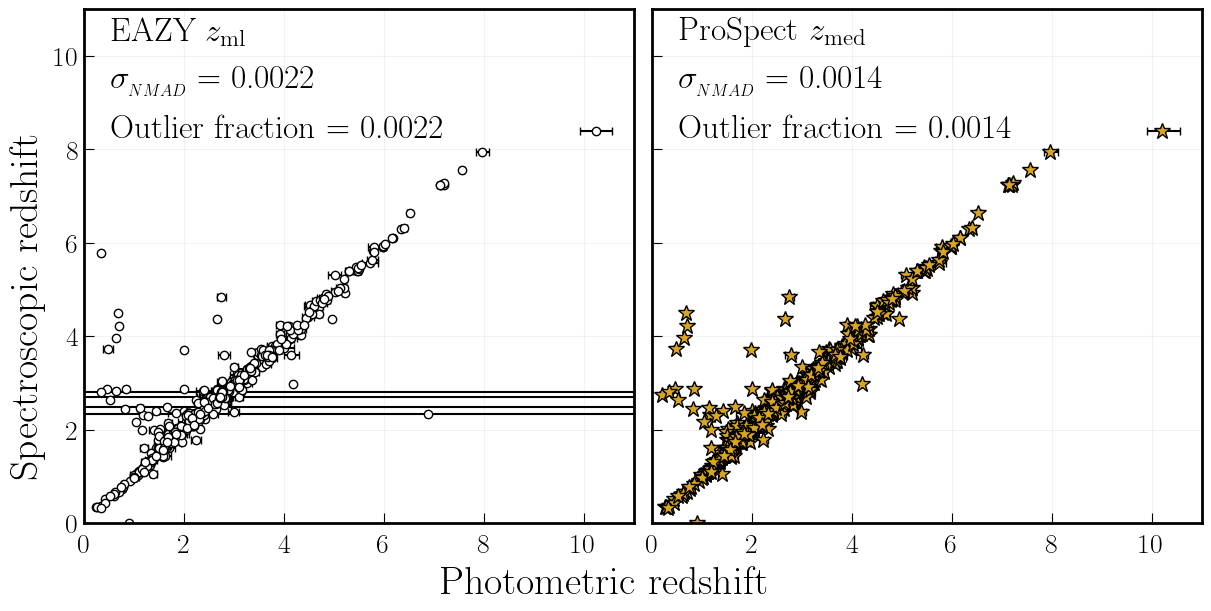

In [199]:
fig, ax = plt.subplots(1,2, figsize = (12,6), layout = "constrained", sharex = True, sharey = True)
# ax = [ax]
# ax[0].scatter(
#     photoz["zeazy"],
#     photoz["zspec"],
#     edgecolor = 'black',
#     facecolor = 'white',
#     s = 50
# )
ax[0].errorbar(
    photoz["zeazy"],
    photoz["zspec"],
    xerr = [photoz["eazyHessianSD"]],
    markersize = 6,
    marker = "o",
    ls = "",
    capsize = 3,
    markeredgecolor = 'black',
    markerfacecolor = 'white',
    ecolor = "black",
    # alpha = 0.6
)
ax[0].text(
    0.05, 0.94, 
    "EAZY $z_{\\mathrm{ml}}$", transform=ax[0].transAxes
)
ax[0].text(
    0.05, 0.85, 
    rf"$\sigma_{{_{{NMAD}}}} = $ {compute_sigmaNMAD(zspec=photoz["zspec"], zphot=photoz["zeazy"]):.4f}", transform=ax[0].transAxes
)
ax[0].text(
    0.05, 0.75, 
    rf"Outlier fraction = {compute_sigmaNMAD(zspec=photoz["zspec"], zphot=photoz["zeazy"]):.4f}", transform=ax[0].transAxes
)

ax[1].text(
    0.05, 0.94, 
    "ProSpect $z_{\\mathrm{med}}$", transform=ax[1].transAxes
)
ax[1].errorbar(
    photoz["zQ50"],
    photoz["zspec"],
    xerr = [photoz["z_lo"], photoz["z_hi"]],
    markersize = 12,
    marker = "*",
    ls = "",
    capsize = 3,
    markeredgecolor = 'black',
    markerfacecolor = 'goldenrod',
    ecolor = "black",
    # alpha = 0.6
)

ax[1].text(
    0.05, 0.85, 
    rf"$\sigma_{{_{{NMAD}}}} = $ {compute_sigmaNMAD(zspec=photoz["zspec"], zphot=photoz["zQ50"]):.4f}", transform=ax[1].transAxes
)
ax[1].text(
    0.05, 0.75, 
    rf"Outlier fraction = {compute_sigmaNMAD(zspec=photoz["zspec"], zphot=photoz["zQ50"]):.4f}", transform=ax[1].transAxes
)

for ax in ax:
    ax.set_xlim([0,11])
    ax.set_ylim([0,11])
    # ax.set_xlim([zbins[0]-0.5, zbins[-1]+0.5])
    # ax.set_ylim([zbins[0]-0.5, zbins[-1]+0.5])
    ax.grid(grid_ls, color = grid_color, alpha = grid_alpha)


fig.supxlabel("Photometric redshift")
fig.supylabel("Spectroscopic redshift")

# ax[0].legend(fancybox = False)

fig.savefig(
    "/Users/jordan/Documents/Epochs/plots/jades_specz.pdf", 
    dpi = 240,
    bbox_inches="tight"
)


# Compare Literature AGN

In [186]:
AGN_compare = pd.read_hdf(h5file, "literatureAGN/compare")
AGN_compare = AGN_compare[AGN_compare["zQ50"] >= zbins[0]]

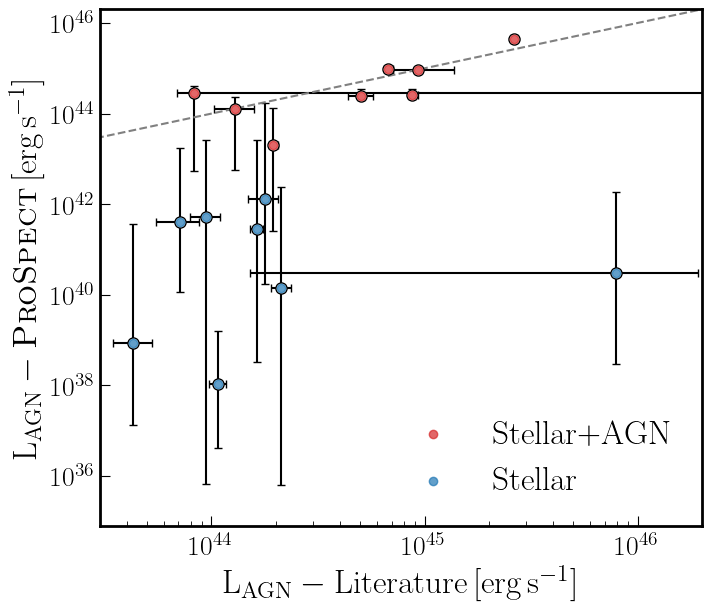

In [202]:
fig, ax = plt.subplots(1,1, figsize = (7,6), layout = "constrained")
ax = [ax]

ax[0].errorbar(
    AGN_compare["AGNlumQ50_lit"],
    AGN_compare["StellarAGN_AGNlumQ50"],
    xerr = [
        AGN_compare["AGNlum_lo_lit"],
        AGN_compare["AGNlum_hi_lit"]
    ],
    yerr = [
        AGN_compare["StellarAGN_AGNlum_lo"],
        AGN_compare["StellarAGN_AGNlum_hi"]
    ],
    markersize = 8,
    marker = "o",
    ls = "",
    capsize = 3,
    markeredgecolor = 'black',
    markerfacecolor = 'white',
    ecolor = "black",
    # alpha = 0.6
)

ax[0].scatter(
    AGN_compare["AGNlumQ50_lit"][AGN_compare["FitType"] == "StellarAGN"],
    AGN_compare["StellarAGN_AGNlumQ50"][AGN_compare["FitType"] == "StellarAGN"],
    color = "tab:red",
    zorder = 200,
    alpha = 0.7,
    label = "Stellar+AGN"
)
ax[0].scatter(
    AGN_compare["AGNlumQ50_lit"][AGN_compare["FitType"] == "Stellar"],
    AGN_compare["StellarAGN_AGNlumQ50"][AGN_compare["FitType"] == "Stellar"],
    color = "tab:blue",
    zorder = 200,
    alpha = 0.7,
    label = "Stellar"
)
ax[0].plot(
    10**np.linspace(35,50,100),
    10**np.linspace(35,50,100),
    ls = "--",
    color = "grey"
)

ax[0].legend(
    frameon = False,
    fancybox = False
)

ax[0].set_xscale("log")
ax[0].set_yscale("log")

ax[0].set_xlim([3e43, 2e46])
ax[0].set_ylim([8e34, 2e46])

ax[0].set_xlabel(r"$\mathrm{L_{AGN} - Literature \, [erg \, s^{-1}]}$")
ax[0].set_ylabel(r"$\mathrm{L_{AGN} - \textsc{ProSpect} \, [erg \, s^{-1}]}$")

fig.savefig(
    "/Users/jordan/Documents/Epochs/plots/Lagn_comparison.pdf", 
    dpi = 240,
    bbox_inches="tight"
)


# Redshift distribution

## Redshift histogram

In [272]:
scholtz25_AGNfrac = pd.read_csv("/Users/jordan/Documents/Epochs/data/literature/AGN-Catalogues/agnfrac/scholtz25.csv")

In [273]:
def calc_hist(ax, prospect_sample):
    stellar_counts, stellar_bin_edges, stellar_patches = ax.hist(
        prospect_sample["zQ50"][prospect_sample["FitType"] == "Stellar"], 
        facecolor = "none",
        edgecolor = "tab:blue", 
        hatch = "//", 
        bins=zbins, 
        label = f"Stellar: {np.sum(prospect_sample["FitType"] == "Stellar")}",
        lw = 2.0
    )
    stellarAGN_counts, stellarAGN_bin_edges, stellarAGN_patches = ax.hist(
        prospect_sample["zQ50"][prospect_sample["FitType"] == "StellarAGN"], 
        facecolor = "none",
        edgecolor = "tab:red", 
        hatch = "\\\\", 
        bins=zbins, 
        label = f"Stellar+AGN: {np.sum(prospect_sample["FitType"] == "StellarAGN")}",
        lw = 2.0
    )
    tot_counts, tot_bin_edges, tot_patches = ax.hist(
        prospect_sample["zQ50"], 
        facecolor = "none",
        edgecolor = "black", 
        # hatch = "\\//",
        # alpha = 0.4, 
        bins=zbins,
        lw = 2,
        label = f"Total: {len(prospect_sample)}",
    )
    return stellar_counts, stellarAGN_counts, tot_counts

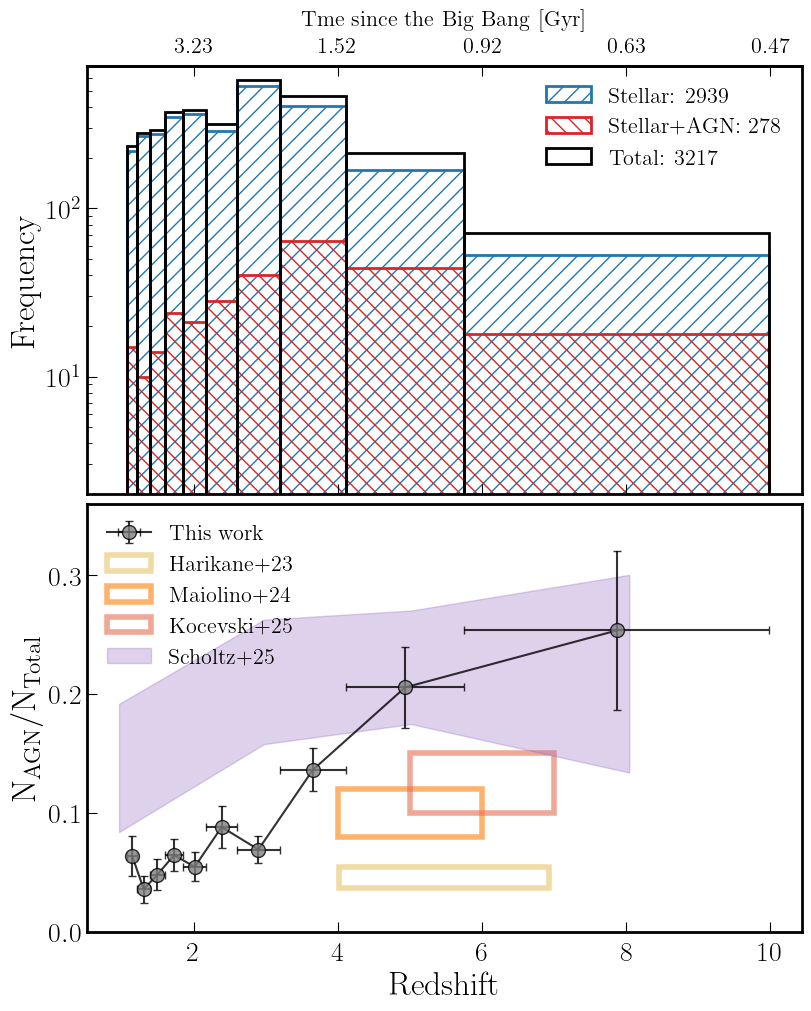

In [296]:
fig, ax = plt.subplots(2,1, figsize = (8,10), layout = 'constrained', sharex = True)

stellar_counts, stellarAGN_counts, tot_counts = calc_hist(ax[0], prospect_sample)

ax[0].legend(
    frameon = False,
    fontsize = 16
)

stellarAGN_err = np.sqrt(stellarAGN_counts)
tot_err = np.sqrt(tot_counts)
ratio_err = stellarAGN_counts/tot_counts * np.sqrt((stellarAGN_err / stellarAGN_counts)**2 + (tot_err / tot_counts)**2)

thiswork_ = ax[1].errorbar(
    zmids, 
    stellarAGN_counts/tot_counts, 
    xerr = [np.diff(zbins)*0.5],
    yerr = [ratio_err],
    marker = "o", 
    markersize = 10,
    markerfacecolor = "grey",
    markeredgecolor = "black",
    color = "black",
    ecolor = "black", 
    alpha = 0.8,
    capsize = 3,
    label = "This work"
)

harikane23_AGNfrac = Patches.Rectangle(
    xy = (4.015, 0.037),
    width = 2.921,
    height = 0.017,
    alpha = 0.6,
    lw = 4,
    facecolor = "none",
    edgecolor = "#e9c46a",
    label = "Harikane+23"
)
maiolino24_AGNfrac = Patches.Rectangle(
    xy = (4.0, 0.08),
    width = 2.0,
    height = 0.04,
    alpha = 0.6,
    lw = 4,
    facecolor = "none",
    edgecolor = "tab:orange",
    label = "Maiolino+24"
)
kocevski25_AGNfrac = Patches.Rectangle(
    xy = (5.0, 0.1),
    width = 2.0,
    height = 0.05,
    alpha = 0.6,
    lw = 4,
    facecolor = "none",
    edgecolor = "#e76f51",
    label = "Kocevski+25"
)
harikane23_AGNfrac_ = ax[1].add_patch(harikane23_AGNfrac)
maiolino24_AGNfrac_ = ax[1].add_patch(maiolino24_AGNfrac)
kocevski25_AGNfrac_ = ax[1].add_patch(kocevski25_AGNfrac)

scholtz25_AGNfrac_ = ax[1].fill_between(
    scholtz25_AGNfrac["z"],
    scholtz25_AGNfrac["agnfracQ16"],
    scholtz25_AGNfrac["agnfracQ84"],
    color = "tab:purple",
    alpha = 0.3,
    label = "Scholtz+25"
)

ax[1].legend(
    handles = (thiswork_, harikane23_AGNfrac_, maiolino24_AGNfrac_, kocevski25_AGNfrac_, scholtz25_AGNfrac_),
    loc = "upper left",
    fontsize = 16,
    frameon = False,
    ncol = 1,
    framealpha = 0.5
)

ax[0].set_yscale("log")

for axx in [ax[0]]:
    ax_top = axx.secondary_xaxis('top')
    ax_top.set_xticks([2.0, 4.0, 6.0, 8.0, 10.0])
    ax_top.set_xticklabels([f"{a:.2f}" for a in cosmo.age([2.0, 4.0, 6.0, 8.0, 10.0]).value], fontsize = 16)
    ax_top.set_xlabel("Tme since the Big Bang [Gyr]", labelpad=8.0, fontsize = 16)

ax[0].set_ylim([2,7e2])
ax[1].set_ylim([0,0.36])

# ax[0].set_xlabel("Redshift")
ax[0].set_ylabel("Frequency")

ax[1].set_xlabel("Redshift")
ax[1].set_ylabel(r"$\mathrm{N_{AGN} / N_{Total}}$")

plt.savefig("/Users/jordan/Documents/Epochs/plots/redshift_hist.pdf",     
            bbox_inches="tight", dpi = 240)

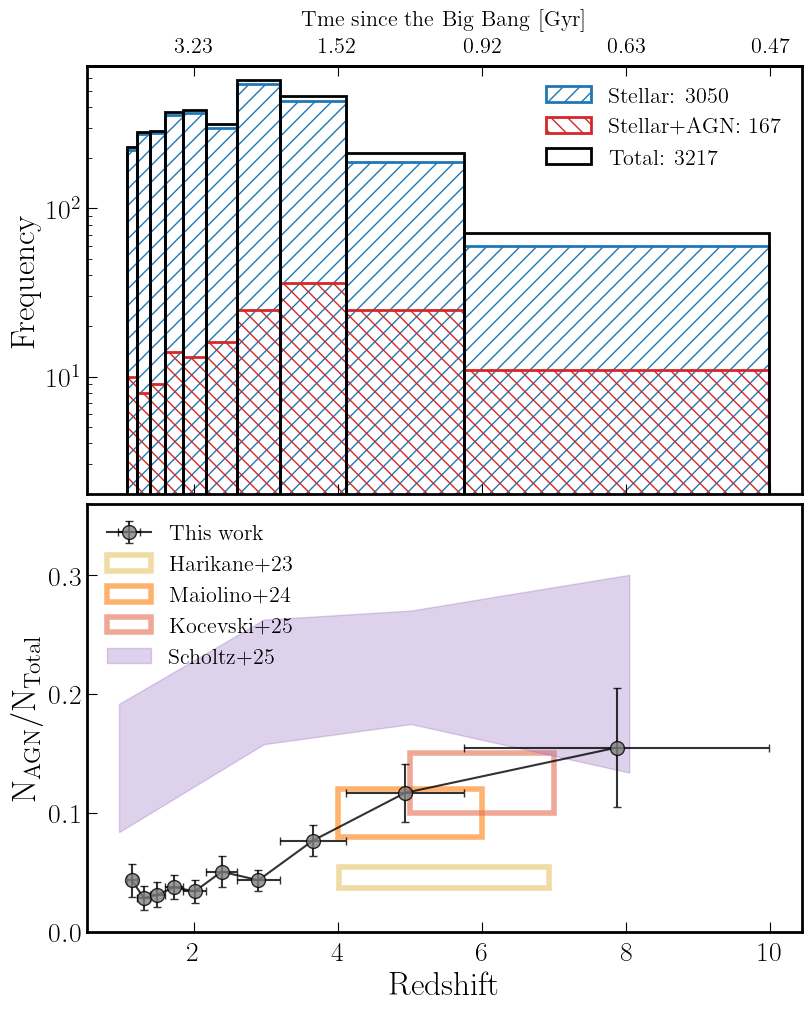

In [297]:
fig, ax = plt.subplots(2,1, figsize = (8,10), layout = 'constrained', sharex = True)

stellar_counts, stellarAGN_counts, tot_counts = calc_hist(ax[0], prospect_sampleDIC)

stellarAGN_err = np.sqrt(stellarAGN_counts)
tot_err = np.sqrt(tot_counts)
ratio_err = stellarAGN_counts/tot_counts * np.sqrt((stellarAGN_err / stellarAGN_counts)**2 + (tot_err / tot_counts)**2)

thiswork_ = ax[1].errorbar(
    zmids, 
    stellarAGN_counts/tot_counts, 
    xerr = [np.diff(zbins)*0.5],
    yerr = [ratio_err],
    marker = "o", 
    markersize = 10,
    markerfacecolor = "grey",
    markeredgecolor = "black",
    color = "black",
    ecolor = "black", 
    alpha = 0.8,
    capsize = 3,
    label = "This work"
)

harikane23_AGNfrac = Patches.Rectangle(
    xy = (4.015, 0.037),
    width = 2.921,
    height = 0.017,
    alpha = 0.6,
    lw = 4,
    facecolor = "none",
    edgecolor = "#e9c46a",
    label = "Harikane+23"
)
maiolino24_AGNfrac = Patches.Rectangle(
    xy = (4.0, 0.08),
    width = 2.0,
    height = 0.04,
    alpha = 0.6,
    lw = 4,
    facecolor = "none",
    edgecolor = "tab:orange",
    label = "Maiolino+24"
)
kocevski25_AGNfrac = Patches.Rectangle(
    xy = (5.0, 0.1),
    width = 2.0,
    height = 0.05,
    alpha = 0.6,
    lw = 4,
    facecolor = "none",
    edgecolor = "#e76f51",
    label = "Kocevski+25"
)
harikane23_AGNfrac_ = ax[1].add_patch(harikane23_AGNfrac)
maiolino24_AGNfrac_ = ax[1].add_patch(maiolino24_AGNfrac)
kocevski25_AGNfrac_ = ax[1].add_patch(kocevski25_AGNfrac)

scholtz25_AGNfrac_ = ax[1].fill_between(
    scholtz25_AGNfrac["z"],
    scholtz25_AGNfrac["agnfracQ16"],
    scholtz25_AGNfrac["agnfracQ84"],
    color = "tab:purple",
    alpha = 0.3,
    label = "Scholtz+25"
)

ax[0].legend(
    frameon = False,
    # loc = "upper left",
    fontsize = 16,
    # bbox_to_anchor = [0.5, 1.0],

)
ax[1].legend(
    handles = (thiswork_, harikane23_AGNfrac_, maiolino24_AGNfrac_, kocevski25_AGNfrac_, scholtz25_AGNfrac_),
    loc = "upper left",
    fontsize = 16,
    frameon = False,
    ncol = 1,
    framealpha = 0.5
)

ax[0].set_yscale("log")

for axx in [ax[0]]:
    ax_top = axx.secondary_xaxis('top')
    ax_top.set_xticks([2.0, 4.0, 6.0, 8.0, 10.0])
    ax_top.set_xticklabels([f"{a:.2f}" for a in cosmo.age([2.0, 4.0, 6.0, 8.0, 10.0]).value], fontsize = 16)
    ax_top.set_xlabel("Tme since the Big Bang [Gyr]", labelpad=8.0, fontsize = 16)

ax[0].set_ylim([2,7e2])
ax[1].set_ylim([0,0.36])

# ax[0].set_xlabel("Redshift")
ax[0].set_ylabel("Frequency")

ax[1].set_xlabel("Redshift")
ax[1].set_ylabel(r"$\mathrm{N_{AGN} / N_{Total}}$")

plt.savefig("/Users/jordan/Documents/Epochs/plots/redshift_histDIC.pdf",     
            bbox_inches="tight", dpi = 240)

Text(0, 0.5, 'Frequency')

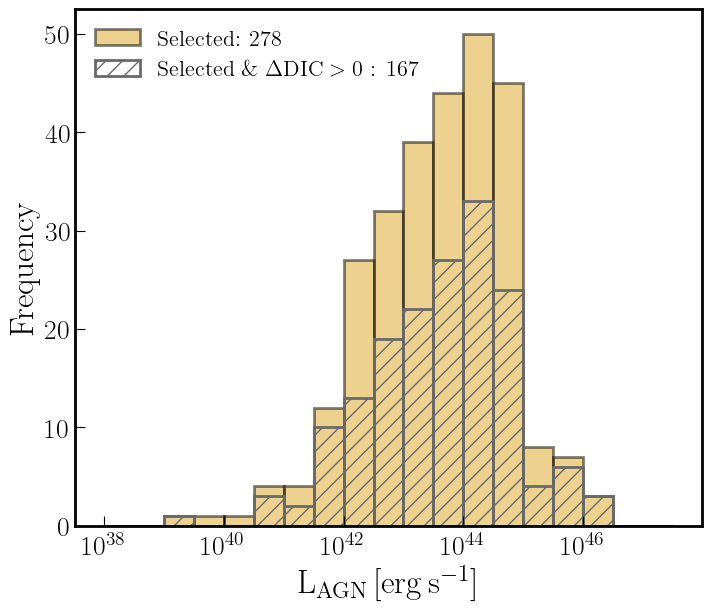

In [65]:
fig, ax = plt.subplots(1,1, figsize = (7,6), layout = 'constrained')

agn_bins = np.arange(38, 48, 0.5)
tot_counts, tot_bin_edges, tot_patches = ax.hist(
    np.log10(prospect_sample["AGNlumQ50"]), 
    facecolor = "goldenrod",
    edgecolor = "black", 
    # hatch = "\\",
    alpha = 0.5, 
    bins=agn_bins,
    lw = 2,
    label = f"Selected: {np.sum(prospect_sample["FitType"] == "StellarAGN")}",
)
tot_countsDIC, tot_bin_edges, tot_patches = ax.hist(
    np.log10(prospect_sampleDIC["AGNlumQ50"]), 
    facecolor = "none",
    edgecolor = "dimgrey", 
    hatch = "//",
    # alpha = 0.4, 
    bins=agn_bins,
    lw = 2,
    label = r"Selected \& $\Delta \mathrm{DIC > 0}$ : " + f"{np.sum(prospect_sampleDIC["FitType"] == "StellarAGN")}",
)

ax.legend(
    frameon = False,
    fontsize = 16
)
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: rf"$10^{{{x:g}}}$"))

ax.set_xlabel(r"$\mathrm{ L_{AGN} \, [erg \, s^{-1}] }$")
ax.set_ylabel(r"Frequency")



## Vs. redshift distributions

In [299]:
def vs_dist_plot_errorbar(ax, z, x, zerr_lo, zerr_hi, xerr_lo, xerr_hi, cols, marker = "o", markersize = 8):
    for zz, xx, zz_lo, zz_hi, xx_lo, xx_hi, cc in zip(z, x, zerr_lo, zerr_hi, xerr_lo, xerr_hi, cols):
        ax.errorbar(
            zz, 
            xx, 
            xerr = [[zz_lo], [zz_hi]],
            yerr = [[xx_lo], [xx_hi]],
            ls = 'none',
            marker = marker, 
            markersize = markersize,
            markerfacecolor = cc,
            markeredgecolor = lighten_color(cc, 1.5),
            ecolor = lighten_color(cc, 1.5), 
            alpha = 0.4,
            capsize = 3
    )

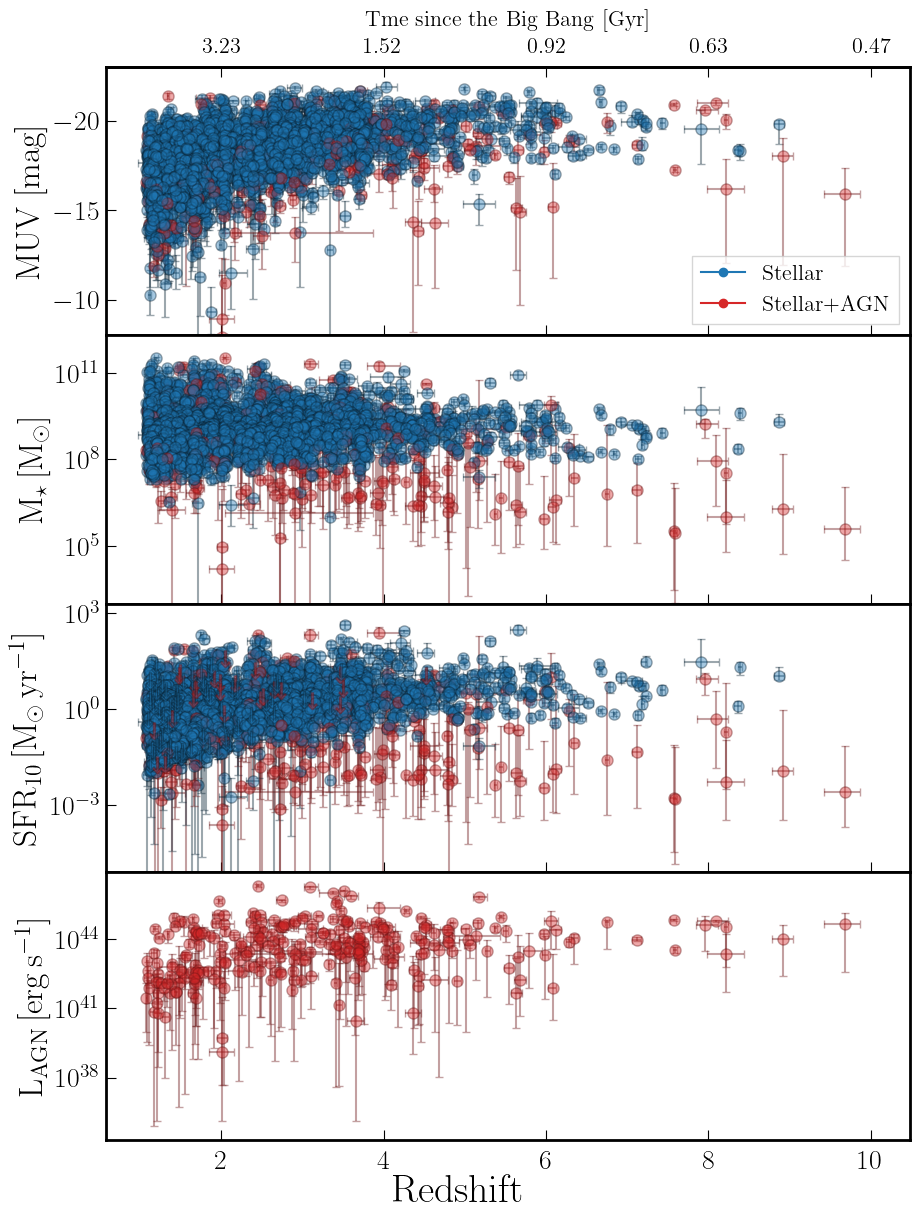

In [301]:
cols = ["tab:blue" if x == "Stellar" else "tab:red" for x in prospect_sample['FitType']]

fig, ax = plt.subplots(4, 1, figsize = (9,12), layout = 'constrained', sharex = True)
fig.get_layout_engine().set(h_pad=0, w_pad=0, hspace=0, wspace=0)

vs_dist_plot_errorbar(
    ax[0],
    prospect_sample["zQ50"], 
    prospect_sample["UV1500Q50"], 
    prospect_sample["z_lo"], 
    prospect_sample["z_hi"],
    prospect_sample["UV1500_lo"], 
    prospect_sample["UV1500_hi"],
    cols
)
ax[0].set_ylim([-8, -23])

vs_dist_plot_errorbar(
    ax[1],
    prospect_sample["zQ50"], 
    prospect_sample["StellarMassQ50"], 
    prospect_sample["z_lo"], 
    prospect_sample["z_hi"],
    prospect_sample["StellarMass_lo"], 
    prospect_sample["StellarMass_hi"],
    cols
)
ax[1].set_yscale('log')
ax[1].set_ylim([1e3, 2e12])

vs_dist_plot_errorbar(
    ax[2],
    starforming_sample["zQ50"], 
    starforming_sample["SFR10Q50"], 
    starforming_sample["z_lo"], 
    starforming_sample["z_hi"],
    starforming_sample["SFR10_lo"], 
    starforming_sample["SFR10_hi"],
    ["tab:blue" if x == "Stellar" else "tab:red" for x in starforming_sample['FitType']]
)
vs_dist_plot_errorbar(
    ax[2],
    quenched_sample["zQ50"], 
    # 1e-5*np.ones(len(quenched_sample["zQ50"])), 
    minimum_SFR10_vals,
    quenched_sample["z_lo"], 
    quenched_sample["z_hi"],
    minimum_SFR10_vals*0.0, 
    minimum_SFR10_vals*0.0,
    ["tab:blue" if x == "Stellar" else "tab:red" for x in quenched_sample['FitType']],
    marker=down_arrow_marker,
    markersize=8*3.0
)
ax[2].set_yscale('log')
ax[2].set_ylim([8e-6, 2e3])

vs_dist_plot_errorbar(
    ax[3],
    prospect_sample["zQ50"], 
    prospect_sample["AGNlumQ50"], 
    prospect_sample["z_lo"], 
    prospect_sample["z_hi"],
    prospect_sample["AGNlum_lo"], 
    prospect_sample["AGNlum_hi"],
    cols
)
ax[3].set_yscale('log')
ax[3].set_ylim([2e35, 8e46])

ax[0].set_xlim([zbins[0]-0.5, zbins[-1]+0.5])
# ax[0].set_xlim([-0.5, zbins[-1]+0.5])

ax[0].set_ylabel("MUV [mag]")
ax[1].set_ylabel(r"$\mathrm{M_{\star} \, [M_{\odot}]}$")
ax[2].set_ylabel(r"$\mathrm{SFR_{10} \, [M_{\odot} \, yr^{-1}]}$")
ax[3].set_ylabel(r"$\mathrm{L_{AGN} \, [erg \, s^{-1}]}$")

ax_top = ax[0].secondary_xaxis('top')
ax_top.set_xticks(ax[0].get_xticks())
ax_top.set_xticklabels([f"{a:.2f}" for a in cosmo.age(ax[0].get_xticks()).value], fontsize = 16)
ax_top.set_xlabel("Tme since the Big Bang [Gyr]", labelpad=8.0, fontsize = 16)

custom_lines = [Line2D([0], [0], color="tab:blue", marker = "o"),
                Line2D([0], [0], color="tab:red", marker = "o")]
ax[0].legend(custom_lines, ["Stellar", "Stellar+AGN"], fontsize = 16, fancybox = False)

fig.supxlabel("Redshift")

fig.savefig(
    "/Users/jordan/Documents/Epochs/plots/astro_quantities_vs_redshift.pdf", 
    dpi = 240,
    bbox_inches="tight"
)

# SFR-Mstar

In [251]:
xm = np.linspace(0, 15, 100)

def dpl_func(x, parm):
    S0, M0, alpha, beta = parm

    mu = 10**(x-M0)
    SFR = S0 - np.log10( mu**(-1.0*alpha) + mu**(-1.0*beta) )

    return(SFR)

thorne21 = pd.read_csv("/Users/jordan/Downloads/SupplementaryMaterials/TableD3_SFMSValues.txt", delimiter="\t")

In [237]:
i=1
zidx = (thorne21["zmed"] >= zbins[i]) & (thorne21["zmed"] < zbins[i+1])
thorne21[["S0", "M0", "alpha", "beta"]][zidx].iloc[0].values

array([ 1.4696, 10.1153,  0.9463,  0.1784])

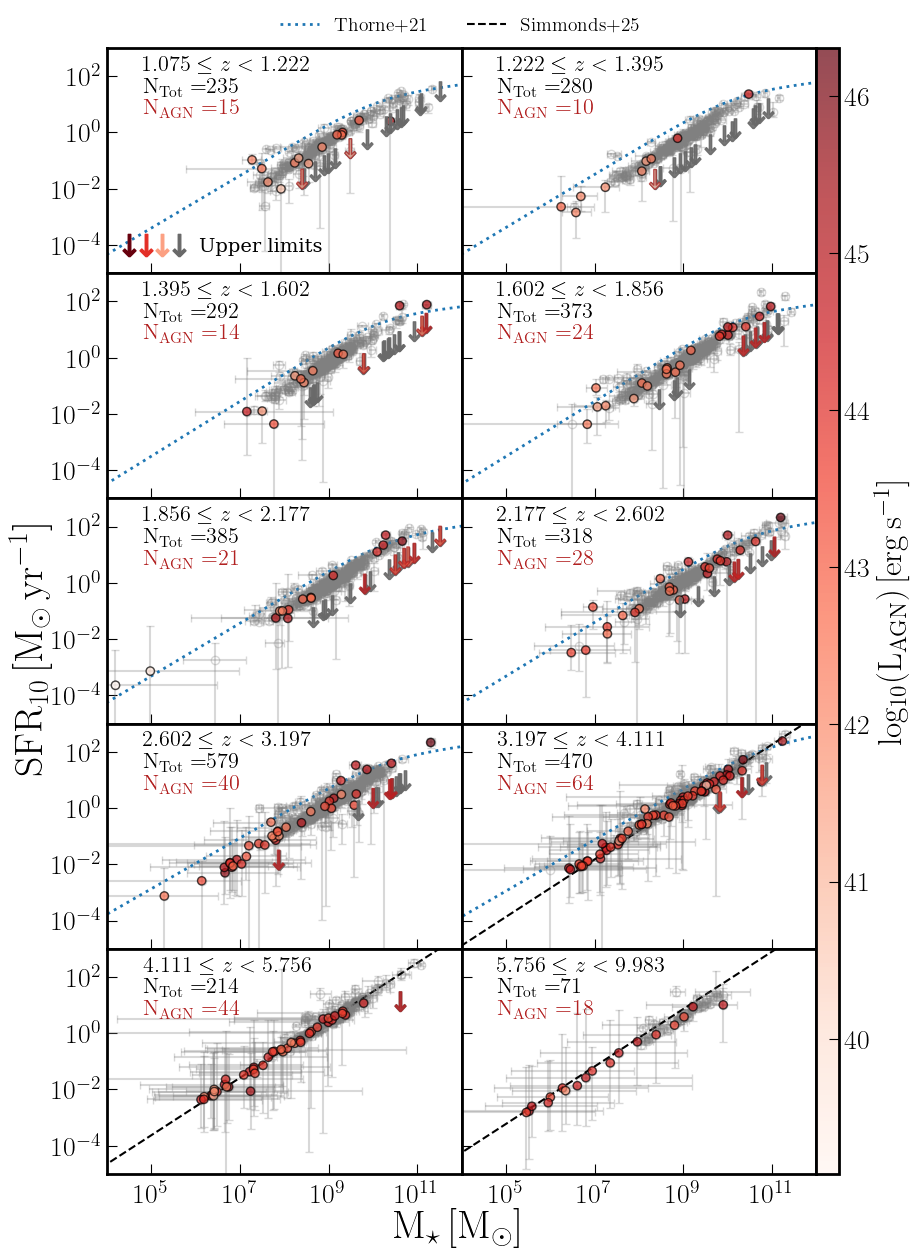

In [270]:
fig, ax = plt.subplots(5,2, figsize = (9,12), sharex=True, sharey=True, layout='constrained')
fig.get_layout_engine().set(h_pad=0, w_pad=0, hspace=0, wspace=0)

ax = ax.flatten()

ztot_zidx = (prospect_sample["zQ50"] >= zbins[0]) & (prospect_sample["zQ50"] < zbins[-1])

tot_agnlum = prospect_sample["AGNlumQ50"]

for i in range(len(zmids)):
    zidx = (starforming_sample["zQ50"] >= zbins[i]) & (starforming_sample["zQ50"] < zbins[i+1])
    zidx_quenched = (quenched_sample["zQ50"] >= zbins[i]) & (quenched_sample["zQ50"] < zbins[i+1])
    zidx_total = (prospect_sample["zQ50"] >= zbins[i]) & (prospect_sample["zQ50"] < zbins[i+1])

    ax[i].errorbar(
        starforming_sample["StellarMassQ50"][zidx],
        starforming_sample["SFR10Q50"][zidx],
        xerr = [starforming_sample["StellarMass_lo"][zidx], starforming_sample["StellarMass_hi"][zidx]],
        yerr = [starforming_sample["SFR10_lo"][zidx], starforming_sample["SFR10_hi"][zidx]],
        fmt = "o",
        markerfacecolor = "none",
        markeredgecolor = "grey",
        ecolor = "grey",
        capsize = 3,
        alpha = 0.3
    )

    sc_ = ax[i].scatter(
        starforming_sample["StellarMassQ50"][zidx],
        starforming_sample["SFR10Q50"][zidx],
        c = np.log10(starforming_sample["AGNlumQ50"][zidx]),
        edgecolor = "black",
        # vmin = 41,
        # vmax = 47,
        vmin = np.nanmin(np.log10(prospect_sample["AGNlumQ50"][ztot_zidx])),
        vmax = np.nanmax(np.log10(prospect_sample["AGNlumQ50"][ztot_zidx])),
        zorder = 100, 
        cmap='Reds',
        alpha = 0.7
    )

    quench_ = ax[i].scatter(
        quenched_sample["StellarMassQ50"][zidx_quenched],
        minimum_SFR10_vals[zidx_quenched],
        zorder = 100, 
        color='dimgrey',
        alpha = 0.9,
        marker = down_arrow_marker,
        edgecolor = "dimgrey",
        s = 800
    )
    sc_quenched_ = ax[i].scatter(
        quenched_sample["StellarMassQ50"][zidx_quenched],
        minimum_SFR10_vals[zidx_quenched],
        c = np.log10(quenched_sample["AGNlumQ50"][zidx_quenched]),
        # vmin = 41,
        # vmax = 47,
        vmin = np.nanmin(np.log10(prospect_sample["AGNlumQ50"][ztot_zidx])),
        vmax = np.nanmax(np.log10(prospect_sample["AGNlumQ50"][ztot_zidx])),
        zorder = 100, 
        cmap='Reds',
        alpha = 0.7,
        marker = down_arrow_marker,
        edgecolor = "firebrick",
        s = 800
    )

    
    # thorne+21
    if zmids[i] < 4:
        S0 = np.interp(
                    xp = thorne21["zmed"],
                    fp = thorne21["S0"],
                    x = zmids[i]
                )
        M0 = np.interp(
                        xp = thorne21["zmed"],
                        fp = thorne21["M0"],
                        x = zmids[i]
                    )
        alpha = np.interp(
                        xp = thorne21["zmed"],
                        fp = thorne21["alpha"],
                        x = zmids[i]
                    )
        beta = np.interp(
                        xp = thorne21["zmed"],
                        fp = thorne21["beta"],
                        x = zmids[i]
                    )
        ax[i].plot(
            10**xm,
            10**dpl_func(x=xm, parm=[S0, M0, alpha, beta]),
            color = "tab:blue", 
            ls = ":",
            lw = 2,
            label = "Thorne+21"
        )
        
    # Simmonds+25
    if zmids[i] >= 3:
        sb = 0.05,
        beta = 0.02
        mu = 2.30

        ssfr = sb * (10**xm / 10**10)**beta * (1 + zmids[i])**mu
        ax[i].plot(
            10**xm,
            ssfr * 10**xm / 1e9,
            color = "black",
            ls = "--",
            label = "Simmonds+25"
        )

    ax[i].text(
        0.1,
        0.9,
        rf"${zbins[i]:.3f} \leq z < {zbins[i+1]:.3f}$",
        transform=ax[i].transAxes,
        fontsize = 16
    )
    ax[i].text(
        0.1,
        0.8,
        r"$\mathrm{N_{Tot} = }$" + f"{sum(zidx_total)}",
        transform=ax[i].transAxes,
        fontsize = 16
    )
    ax[i].text(
            0.1,
            0.7,
            r"$\mathrm{N_{AGN} = }$" + f"{sum(prospect_sample["FitType"][zidx_total] == "StellarAGN")}",
            transform=ax[i].transAxes,
            fontsize = 16,
            color = "firebrick"
        )

    ax[i].set_xscale('log')
    ax[i].set_yscale('log')

    ax[i].set_xlim([1e4, 1e12])
    ax[i].set_ylim([1e-5, 1e3])

    ax[i].set_xticks([1e5, 1e7, 1e9, 1e11])
    ax[i].set_yticks([1e-4, 1e-2, 1e0, 1e2])

# cbar_ax = fig.add_axes([0.87, 0.05, 0.02, 0.9])  # [left, bottom, width, height]

handles, labels = ax[7].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.04),  # above the figure
    ncol = 2,
    # ncol=len(labels),            # optional: put all entries on one row
    fontsize=14,
    fancybox=False,
    frameon=False
)

plt.rcParams["text.usetex"] = False
custom_lines = [
    Line2D([0], [0], color=get_n_colors(cmap_name="Reds", n=4)[3],
           marker='$\u2193$', markersize=8*2, linestyle='None'),
    Line2D([0], [0], color=get_n_colors(cmap_name="Reds", n=4)[2],
           marker='$\u2193$', markersize=8*2, linestyle='None'),
    Line2D([0], [0], color=get_n_colors(cmap_name="Reds", n=4)[1],
           marker='$\u2193$', markersize=8*2, linestyle='None'),
    Line2D([0], [0], color="dimgrey",
           marker='$\u2193$', markersize=8*2, linestyle='None'),
]
ax[0].legend(
    [tuple(custom_lines)],
    ["Upper limits"],
    fontsize=14,
    frameon=False,
    handler_map={tuple: HandlerTuple(ndivide=None)},
    handlelength=3,   # widen the entry so 3 markers don't overlap/crowd
    loc = "lower left"
)
plt.rcParams["text.usetex"] = True

cbar = fig.colorbar(sc_, ax = ax, label=r'$\mathrm{log_{10}(L_{AGN}) \, [erg \, s^{-1}]}$', pad = 0.0, aspect = 50)

fig.supxlabel(r"$\mathrm{M_{\star} \, [M_{\odot}]}$")
fig.supylabel(r"$\mathrm{SFR_{10} \, [M_{\odot} \, yr^{-1}]}$")

fig.savefig(
    "/Users/jordan/Documents/Epochs/plots/sfr-mstar-z.pdf", 
    dpi = 240,
    bbox_inches="tight"
)


# Mstar LAGN

Text(-0.06, 0.5, '$\\mathrm{L_{AGN} \\, [erg \\, s^{-1}]}$')

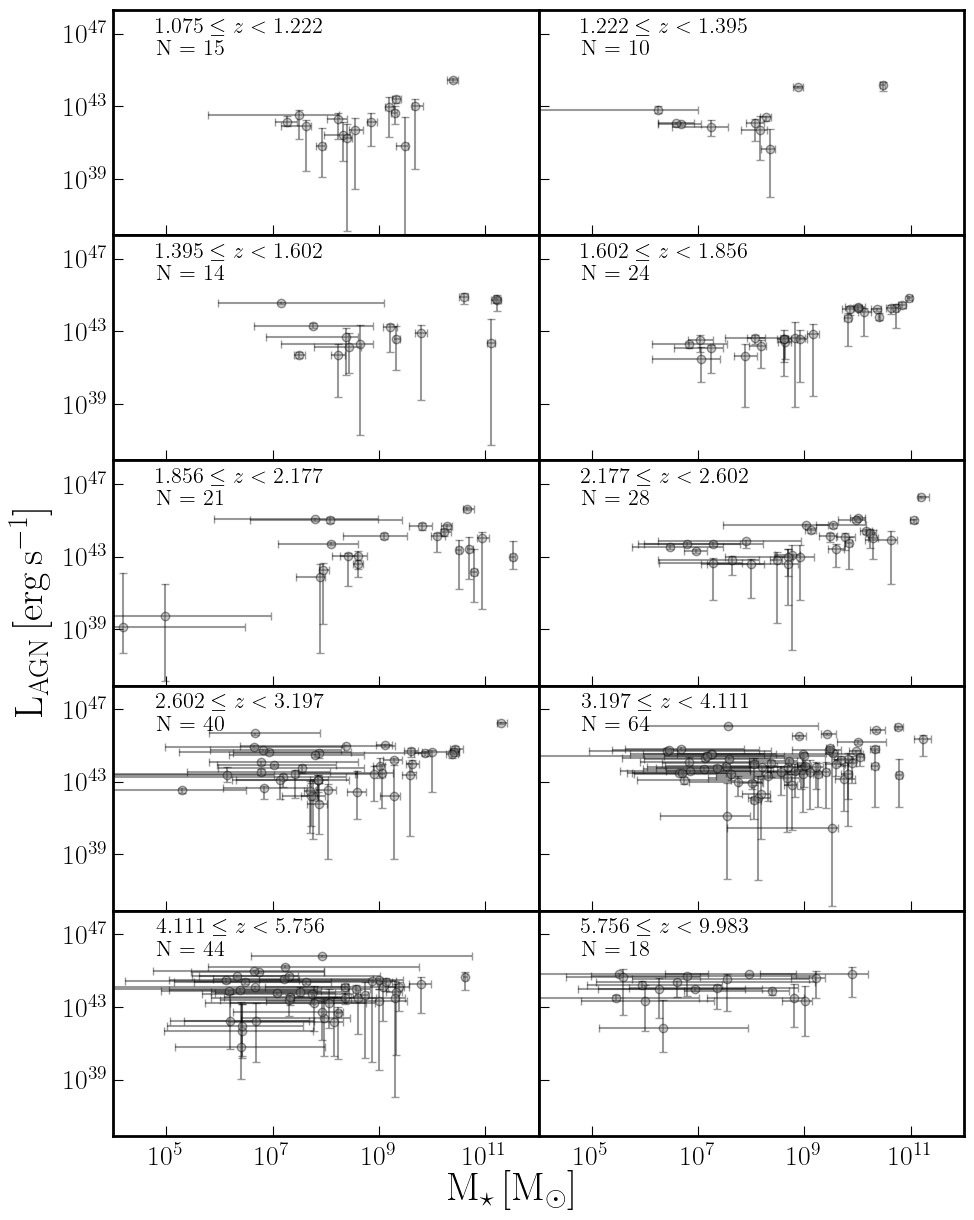

In [69]:
fig, ax = plt.subplots(5,2, figsize = (9,12), sharex=True, sharey=True, layout='constrained')
fig.get_layout_engine().set(h_pad=0, w_pad=0.0, hspace=0, wspace=0)

ax = ax.flatten()

ztot_zidx = (prospect_sample["zQ50"] >= zbins[0]) & (prospect_sample["zQ50"] < zbins[-1])

for i in range(len(zmids)):
    zidx = (prospect_sample["zQ50"] >= zbins[i]) & (prospect_sample["zQ50"] < zbins[i+1])

    ax[i].errorbar(
        prospect_sample["StellarMassQ50"][zidx],
        prospect_sample["AGNlumQ50"][zidx],
        xerr = [prospect_sample["StellarMass_lo"][zidx], prospect_sample["StellarMass_hi"][zidx]],
        yerr = [prospect_sample["AGNlum_lo"][zidx], prospect_sample["AGNlum_hi"][zidx]],
        fmt = "o",
        markerfacecolor = "grey",
        markeredgecolor = "black",
        ecolor = "black",
        capsize = 3,
        alpha = 0.4
    )

    ax[i].text(
        0.1,
        0.9,
        rf"${zbins[i]:.3f} \leq z < {zbins[i+1]:.3f}$",
        transform=ax[i].transAxes,
        fontsize = 16
    )
    ax[i].text(
        0.1,
        0.8,
        f"N = {sum(~np.isnan(prospect_sample["AGNlumQ50"][zidx]))}",
        transform=ax[i].transAxes,
        fontsize = 16
    )

    ax[i].set_xscale('log')
    ax[i].set_yscale('log')

    ax[i].set_xlim([1e4, 1e12])
    ax[i].set_ylim([8e35, 2e48])

    ax[i].set_xticks([1e5, 1e7, 1e9, 1e11])

fig.supxlabel(r"$\mathrm{M_{\star} \, [M_{\odot}]}$")
fig.supylabel(r"$\mathrm{L_{AGN} \, [erg \, s^{-1}]}$", x = -0.06)

# fig.savefig(
#     "/Users/jordan/Documents/Epochs/plots/sfr-mstar-z.pdf", 
#     dpi = 240,
#     bbox_inches="tight"
# )

# Mstar vs MUV

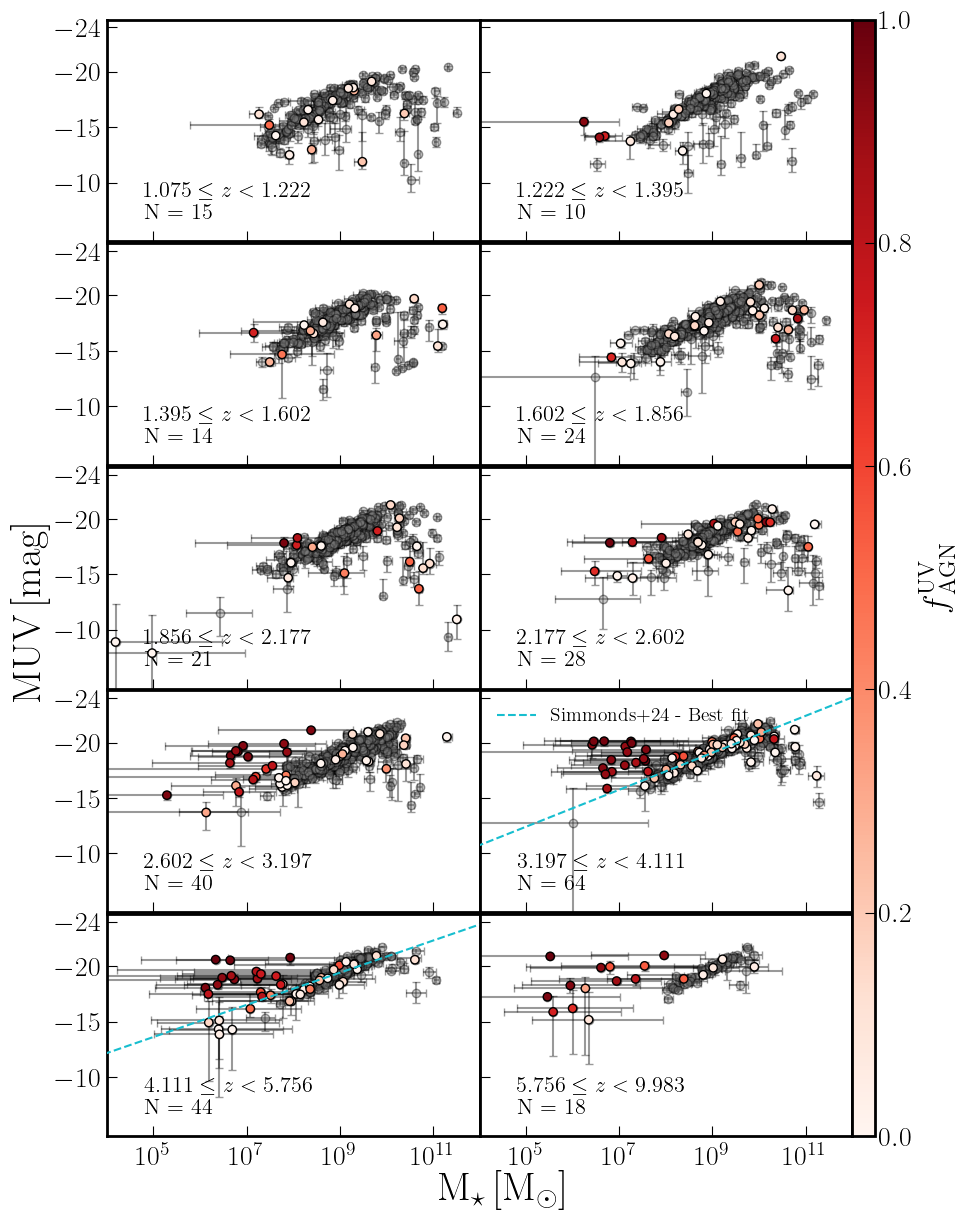

In [70]:
fig, ax = plt.subplots(5,2, figsize = (9,12), sharex=True, sharey=True, layout='constrained')
fig.get_layout_engine().set(h_pad=0, w_pad=0.0, hspace=0, wspace=0)

ax = ax.flatten()

ztot_zidx = (prospect_sample["zQ50"] >= zbins[0]) & (prospect_sample["zQ50"] < zbins[-1])

MUV_AGN_ratio = pow(10, -0.4 * (prospect_sample["UV1500AGNQ50"] - prospect_sample["UV1500Q50"]))

xMstar = np.linspace(1.5, 15.5, 100)

for i in range(len(zmids)):
    zidx = (prospect_sample["zQ50"] >= zbins[i]) & (prospect_sample["zQ50"] < zbins[i+1])

    ax[i].errorbar(
        prospect_sample["StellarMassQ50"][zidx],
        prospect_sample["UV1500Q50"][zidx],
        xerr = [prospect_sample["StellarMass_lo"][zidx], prospect_sample["StellarMass_hi"][zidx]],
        yerr = [prospect_sample["UV1500_lo"][zidx], prospect_sample["UV1500_hi"][zidx]],
        fmt = "o",
        markerfacecolor = "grey",
        markeredgecolor = "black",
        ecolor = "black",
        capsize = 3,
        alpha = 0.4
    )

    sc_ = ax[i].scatter(
        prospect_sample["StellarMassQ50"][zidx],
        prospect_sample["UV1500Q50"][zidx],
        c = MUV_AGN_ratio[zidx],
        edgecolor = "black",
        vmin = 0.0,
        vmax = 1.0,
        zorder = 100, 
        cmap='Reds',
        alpha = 1.0
    )

    if i == 7:
        ax[i].plot(
            10**xMstar,
            (xMstar - 9.25)/-0.6 - 19.5,
            color = "tab:cyan",
            ls = "--",
            label = "Simmonds+24 - Best fit",
            zorder = 200
        )
        ax[i].legend(
            fontsize = 14,
            frameon = False,
            loc = "upper left"
        )
    if i == 8:
        ax[i].plot(
            10**xMstar,
            (xMstar - 9.06)/-0.69 - 19.5,
            color = "tab:cyan",
            ls = "--",
            label = "Simmonds+24 - Best fit",
            zorder = 200
        )

    ax[i].text(
        0.1,
        0.2,
        rf"${zbins[i]:.3f} \leq z < {zbins[i+1]:.3f}$",
        transform=ax[i].transAxes,
        fontsize = 16
    )
    ax[i].text(
        0.1,
        0.1,
        f"N = {sum(~np.isnan(prospect_sample["AGNlumQ50"][zidx]))}",
        transform=ax[i].transAxes,
        fontsize = 16
    )
    ax[i].set_xscale('log')

    ax[i].set_xlim([1e4, 1e12])
    ax[i].set_ylim([-4.7, -24.7])

    ax[i].set_xticks([1e5, 1e7, 1e9, 1e11])
    ax[i].set_yticks([-10, -15, -20, -24])

cbar = fig.colorbar(sc_, ax = ax, label=r'$f\mathrm{_{AGN}^{UV}}$', pad = 0.0, aspect = 50)

fig.supxlabel(r"$\mathrm{M_{\star} \, [M_{\odot}]}$")
fig.supylabel(r"$\mathrm{MUV \, [mag]}$", x = -0.05)

fig.savefig(
    "/Users/jordan/Documents/Epochs/plots/MUV-mstar-z.pdf", 
    dpi = 240,
    bbox_inches="tight"
)

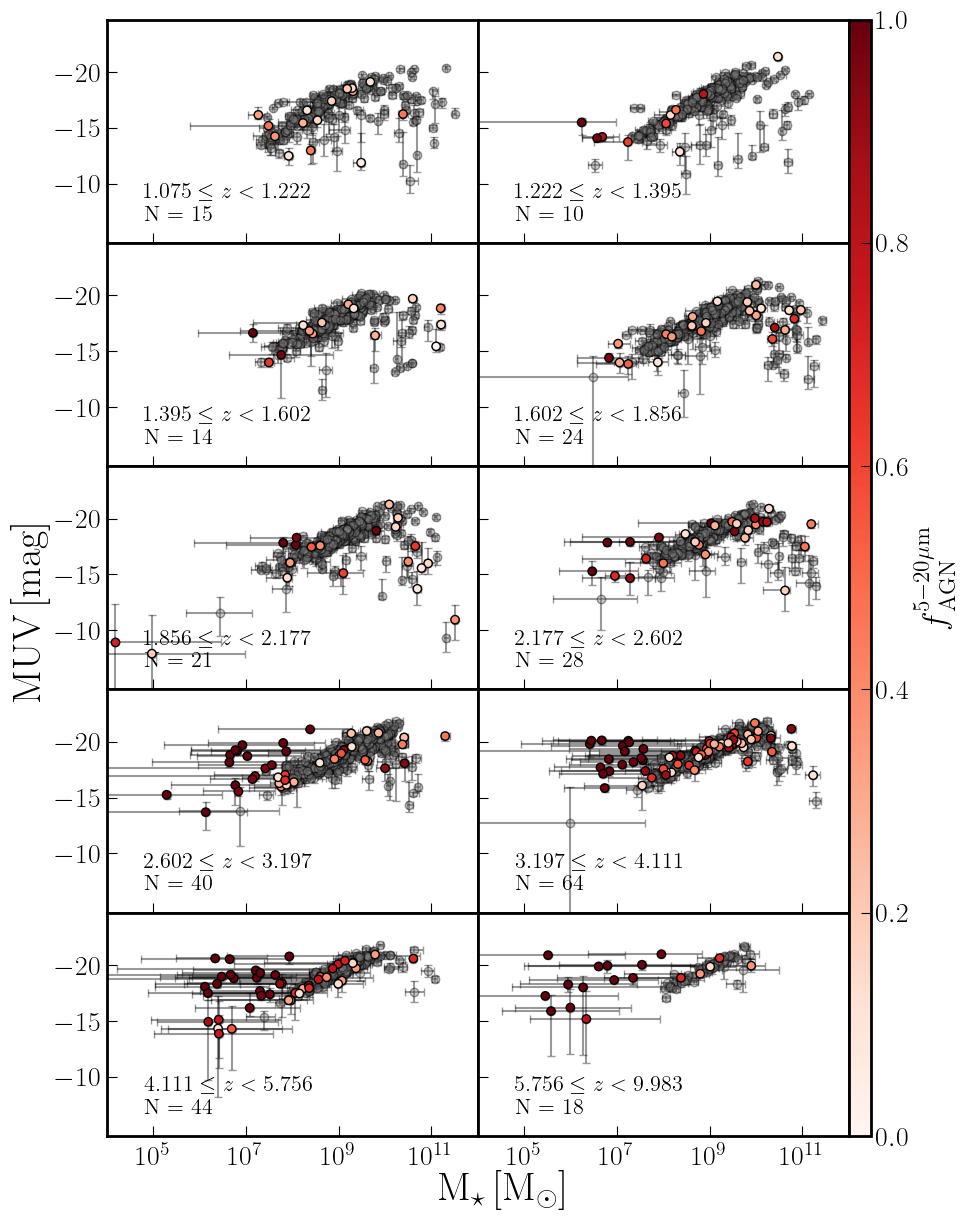

In [73]:
fig, ax = plt.subplots(5,2, figsize = (9,12), sharex=True, sharey=True, layout='constrained')
fig.get_layout_engine().set(h_pad=0, w_pad=0.0, hspace=0, wspace=0)

ax = ax.flatten()

ztot_zidx = (prospect_sample["zQ50"] >= zbins[0]) & (prospect_sample["zQ50"] < zbins[-1])

MUV_AGN_ratio = pow(10, -0.4 * (prospect_sample["UV1500AGNQ50"] - prospect_sample["UV1500Q50"]))

for i in range(len(zmids)):
    zidx = (prospect_sample["zQ50"] >= zbins[i]) & (prospect_sample["zQ50"] < zbins[i+1])

    ax[i].errorbar(
        prospect_sample["StellarMassQ50"][zidx],
        prospect_sample["UV1500Q50"][zidx],
        xerr = [prospect_sample["StellarMass_lo"][zidx], prospect_sample["StellarMass_hi"][zidx]],
        yerr = [prospect_sample["UV1500_lo"][zidx], prospect_sample["UV1500_hi"][zidx]],
        fmt = "o",
        markerfacecolor = "grey",
        markeredgecolor = "black",
        ecolor = "black",
        capsize = 3,
        alpha = 0.4
    )

    sc_ = ax[i].scatter(
        prospect_sample["StellarMassQ50"][zidx],
        prospect_sample["UV1500Q50"][zidx],
        c = [np.nan if x == 0 else x for x in prospect_sample["AGN_Dale_frac_Q50"][zidx]],
        edgecolor = "black",
        vmin = 0.0,
        vmax = 1.0,
        zorder = 100, 
        cmap='Reds',
        alpha = 1.0
    )
    ax[i].text(
            0.1,
            0.2,
            rf"${zbins[i]:.3f} \leq z < {zbins[i+1]:.3f}$",
            transform=ax[i].transAxes,
            fontsize = 16
    )
    ax[i].text(
        0.1,
        0.1,
        f"N = {sum(~np.isnan(prospect_sample["AGNlumQ50"][zidx]))}",
        transform=ax[i].transAxes,
        fontsize = 16
    )
    ax[i].set_xscale('log')

    ax[i].set_xlim([1e4, 1e12])
    ax[i].set_ylim([-4.7, -24.7])

    ax[i].set_xticks([1e5, 1e7, 1e9, 1e11])
    ax[i].set_yticks([-10, -15, -20])

cbar = fig.colorbar(sc_, ax = ax, label=r'$f\mathrm{_{AGN}^{5-20\mu m}}$', pad = 0.0, aspect = 50)

fig.supxlabel(r"$\mathrm{M_{\star} \, [M_{\odot}]}$")
fig.supylabel(r"$\mathrm{MUV \, [mag]}$", x = -0.05)

fig.savefig(
    "/Users/jordan/Documents/Epochs/plots/MUV-mstar-z_AGNfrac.pdf", 
    dpi = 240,
    bbox_inches="tight"
)

# Mstar vs. accretion rates

In [37]:
sfr_bhar_dpl_fits = [
    pd.read_hdf(
        h5file, 
        f"SFRBHAR/fits/{i+1}"
    ) for i in range(len(zmids))
]
sfr_bhar_dpl_params = pd.read_hdf(h5file, "SFRBHAR/Params")

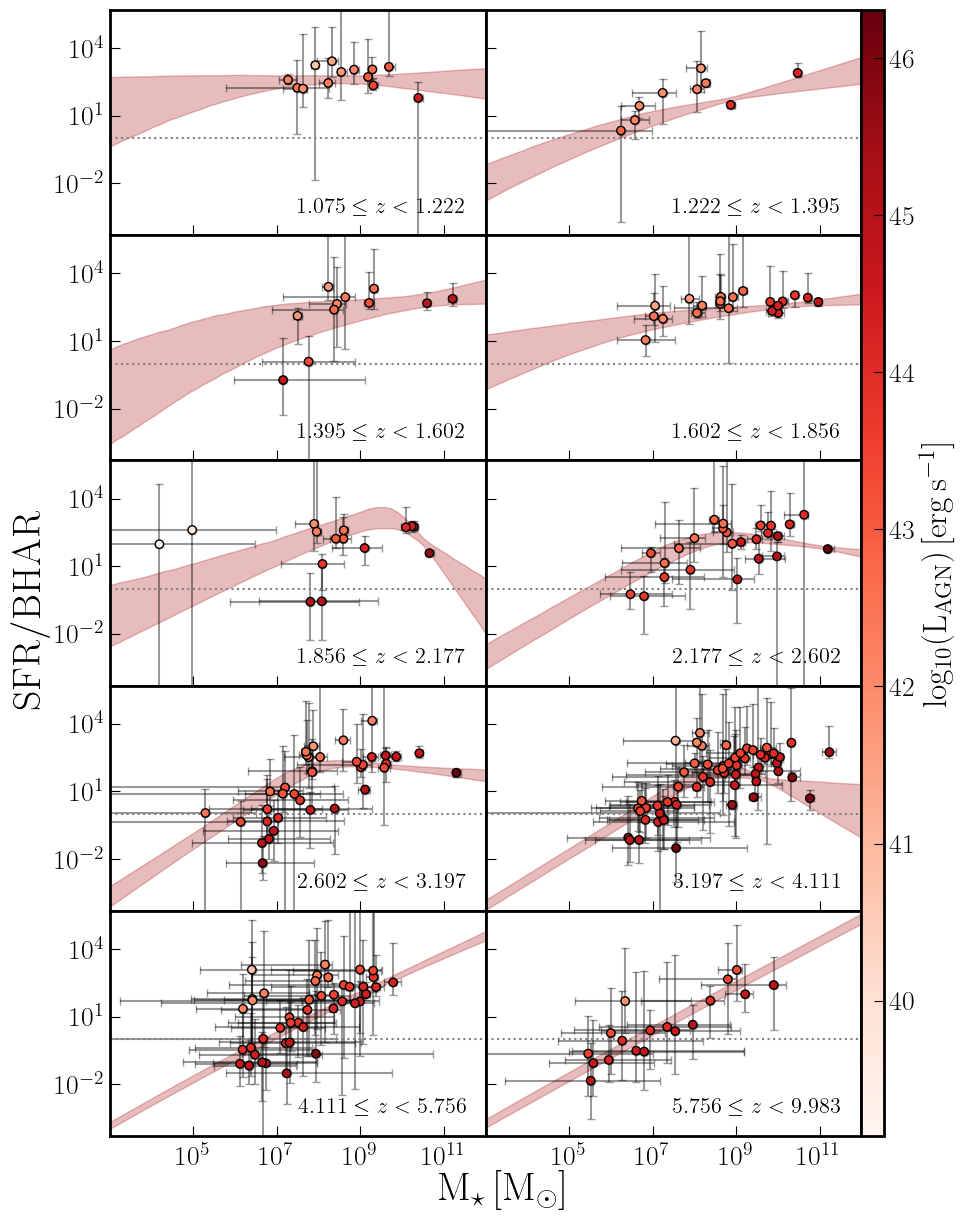

In [38]:
fig, ax = plt.subplots(5,2, figsize = (9,12), sharex=True, sharey=True, layout='constrained')
fig.get_layout_engine().set(h_pad=0, w_pad=0.0, hspace=0, wspace=0)

ax = ax.flatten()

ztot_zidx = (prospect_robust["zQ50"] >= zbins[0]) & (prospect_robust["zQ50"] < zbins[-1])

for i in range(len(zmids)):
    zidx = (prospect_sample["zQ50"] >= zbins[i]) & (prospect_sample["zQ50"] < zbins[i+1]) & (SMBH_results_sample["lowerlim"] == 0)
    # zidx_quenched = (prospect_sample["zQ50"] >= zbins[i]) & (prospect_sample["zQ50"] < zbins[i+1]) & (SMBH_results_sample["lowerlim"] == 1)

    ax[i].errorbar(
        prospect_sample["StellarMassQ50"][zidx],
        SMBH_results_sample["BHARSFR10Q50"][zidx],
        xerr = [prospect_sample["StellarMass_lo"][zidx], prospect_sample["StellarMass_hi"][zidx]],
        yerr = [SMBH_results_sample["BHARSFR10_lo"][zidx], SMBH_results_sample["BHARSFR10_hi"][zidx]],
        fmt = "o",
        markerfacecolor = "grey",
        markeredgecolor = "black",
        ecolor = "black",
        capsize = 3,
        alpha = 0.4
    )
    sc_ = ax[i].scatter(
        prospect_sample["StellarMassQ50"][zidx],
        SMBH_results_sample["BHARSFR10Q50"][zidx],
        c = np.log10(prospect_sample["AGNlumQ50"][zidx]),
        edgecolor = "black",
        vmin = np.nanmin(np.log10(prospect_sample["AGNlumQ50"][ztot_zidx])),
        vmax = np.nanmax(np.log10(prospect_sample["AGNlumQ50"][ztot_zidx])),
        zorder = 100, 
        cmap='Reds',
        alpha = 1.0
    )

    fit_ = ax[i].fill_between(
        10**sfr_bhar_dpl_fits[i]["x"],
        10**(sfr_bhar_dpl_fits[i]["Q16"]),
        10**(sfr_bhar_dpl_fits[i]["Q84"]),
        color = "firebrick",
        alpha = 0.3
    )
    # ax[i].errorbar(
    #     [10**sfr_bhar_dpl_params["MbreakQ50"][i]],
    #     [1],
    #     xerr=[
    #         [10**sfr_bhar_dpl_params["MbreakQ50"][i] - 10**sfr_bhar_dpl_params["MbreakQ16"][i]],
    #         [10**sfr_bhar_dpl_params["MbreakQ84"][i] - 10**sfr_bhar_dpl_params["MbreakQ50"][i]]
    #     ],
    #     marker="*",
    #     markersize=12,
    #     capsize=3,
    #     markerfacecolor="goldenrod",
    #     markeredgecolor="black",
    #     ecolor="black",
    #     zorder=100
    # )

    # sc_quenched_ = ax[i].scatter(
    #     prospect_sample["StellarMassQ50"][zidx_quenched],
    #     BHAR_SFR_sample["lowerlimVal"][zidx_quenched],
    #     c = np.log10(quenched_sample["AGNlumQ50"][zidx_quenched]),
    #     # vmin = 41,
    #     # vmax = 47,
    #     vmin = np.nanmin(np.log10(prospect_sample["AGNlumQ50"][ztot_zidx])),
    #     vmax = np.nanmax(np.log10(prospect_sample["AGNlumQ50"][ztot_zidx])),
    #     zorder = 100, 
    #     cmap='Reds',
    #     alpha = 0.7,
    #     marker = up_arrow_marker,
    #     edgecolor = "firebrick",
    #     s = 800
    # )

    ax[i].axhline(1, ls = ":", color = "grey")
    # ax[i].axvline(1e7, ls = "--", color = "grey", label = "Inayoshi+26")

    ax[i].text(
        0.5,
        0.1,
        rf"${zbins[i]:.3f} \leq z < {zbins[i+1]:.3f}$",
        transform=ax[i].transAxes,
        fontsize = 16
    )
    # ax[i].text(
    #     0.1,
    #     0.2,
    #     f"N = { sum(~np.isnan(prospect_sample["AGNlumQ50"][zidx])) + sum(~np.isnan(prospect_sample["AGNlumQ50"][zidx_quenched]))}",
    #     transform=ax[i].transAxes,
    #     fontsize = 16
    # )

    ax[i].set_xscale('log')
    ax[i].set_yscale('log')

    ax[i].set_xlim([1e3, 1e12])
    ax[i].set_ylim([5e-5, 5e5])

    ax[i].set_xticks([1e5, 1e7, 1e9, 1e11])

    # cbar = fig.colorbar(sc_, ax = ax[i])

    # ax[i].set_yticks([1e-4, 1e-2, 1e0, 1e2])

# cbar_ax = fig.add_axes([0.87, 0.05, 0.02, 0.9])  # [left, bottom, width, height]
cbar = fig.colorbar(sc_, ax = ax, label=r'$\mathrm{log_{10}(L_{AGN}) \, [erg \, s^{-1}]}$', pad = 0.0, aspect = 50)

fig.supxlabel(r"$\mathrm{M_{\star} \, [M_{\odot}]}$")
fig.supylabel(r"$\mathrm{SFR / BHAR}$", x = -0.05)

fig.savefig(
    "/Users/jordan/Documents/Epochs/plots/bhar_sfr-mstar-z.pdf", 
    dpi = 240,
    bbox_inches="tight"
)

## Compute redshift evolution of SFR/BHAR fit parameters

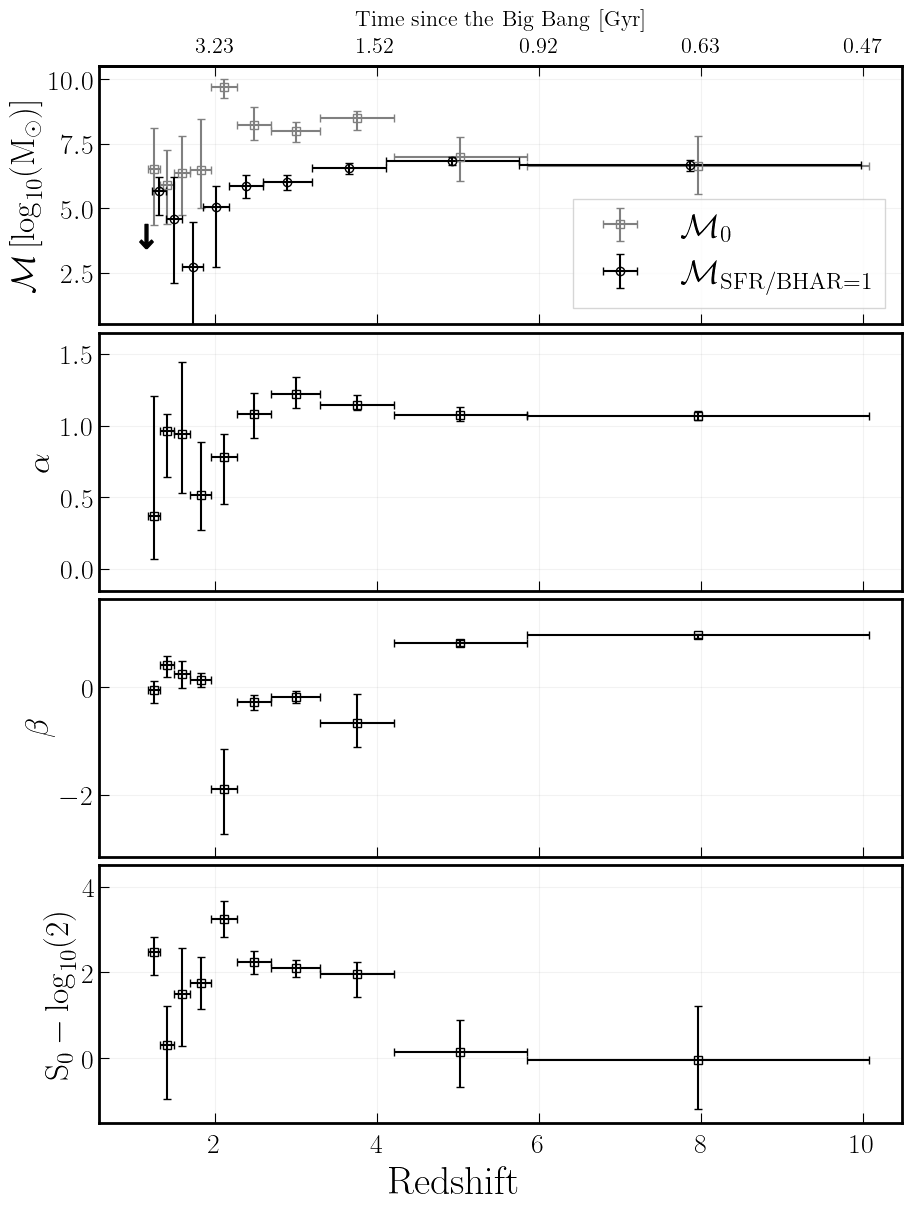

In [401]:
fig, ax = plt.subplots(4, 1, layout = "constrained", figsize = (9, 12), sharex = True)

ax[0].errorbar(
    zmids+0.1,
    sfr_bhar_dpl_params["M0Q50"],
    xerr = (np.diff(zbins)*0.5),
    yerr = [
        sfr_bhar_dpl_params["M0_lo"],
        sfr_bhar_dpl_params["M0_hi"]
    ],
    fmt = "s",
    capsize = 3,
    markerfacecolor = "none",
    markeredgecolor = "grey",
    ecolor = "grey",
    label = r"$\mathcal{M}_{0}$"
)
ax[0].errorbar(
    zmids[1:],
    sfr_bhar_dpl_params["MbreakQ50"][1:],
    xerr = (np.diff(zbins)*0.5)[1:],
    yerr = [
        sfr_bhar_dpl_params["Mbreak_lo"][1:],
        sfr_bhar_dpl_params["Mbreak_hi"][1:]
    ],
    fmt = "o",
    capsize = 3,
    markerfacecolor = "none",
    markeredgecolor = "black",
    ecolor = "black",
    label = r"$\mathcal{M}_{\mathrm{SFR/BHAR = 1}}$"
)
ax[0].scatter(
    zmids[0],
    sfr_bhar_dpl_params["MbreakQ84"][0],
    marker = down_arrow_marker,
    color = "black",
    s = 1200
)

# ax[0].axhline(7, ls = "--", color = "black")

ax[1].errorbar(
    zmids+0.1,
    sfr_bhar_dpl_params["alphaQ50"],
    xerr = (np.diff(zbins)*0.5),
    yerr = [
        sfr_bhar_dpl_params["alpha_lo"],
        sfr_bhar_dpl_params["alpha_hi"]
    ],
    fmt = "s",
    capsize = 3,
    markerfacecolor = "none",
    markeredgecolor = "black",
    ecolor = "black"
)

ax[2].errorbar(
    zmids+0.1,
    sfr_bhar_dpl_params["betaQ50"],
    xerr = (np.diff(zbins)*0.5),
    yerr = [
        sfr_bhar_dpl_params["beta_lo"],
        sfr_bhar_dpl_params["beta_hi"]
    ],
    fmt = "s",
    capsize = 3,
    markerfacecolor = "none",
    markeredgecolor = "black",
    ecolor = "black"
)

ax[3].errorbar(
    zmids+0.1,
    sfr_bhar_dpl_params["S0Q50"] - np.log10(2),
    xerr = (np.diff(zbins)*0.5),
    yerr = [
        sfr_bhar_dpl_params["S0_lo"],
        sfr_bhar_dpl_params["S0_hi"]
    ],
    fmt = "s",
    capsize = 3,
    markerfacecolor = "none",
    markeredgecolor = "black",
    ecolor = "black"
)

for axx in ax:
    axx.grid(color = "grey", alpha = 0.1)
#     axx.axvline(2.0, color = "black", ls = "--")

ax[0].legend(
    fancybox = False
)
ax[0].set_xlim([zbins[0]-0.5, zbins[-1]+0.5])

ax[0].set_ylim([0.5,10.5])
ax[1].set_ylim([-0.15, 1.65])
ax[2].set_ylim([-3.15, 1.65])
ax[3].set_ylim([-1.5, 4.5])

ax_top = ax[0].secondary_xaxis('top')
ax_top.set_xticks(ax[0].get_xticks())
ax_top.set_xticklabels([f"{a:.2f}" for a in cosmo.age(ax[0].get_xticks()).value], fontsize = 16)
ax_top.set_xlabel("Time since the Big Bang [Gyr]", labelpad=8.0, fontsize = 16)

ax[0].set_ylabel(r"$\mathrm{ \mathcal{M} \, [\log_{10}(M_{\odot})] }$")
ax[1].set_ylabel(r"$\mathrm{ \alpha }$")
ax[2].set_ylabel(r"$\mathrm{ \beta }$")
ax[3].set_ylabel(r"$\mathrm{ S_{0} - \log_{10}(2)}$")

fig.supxlabel("Redshift")

fig.savefig(
    "/Users/jordan/Documents/Epochs/plots/sfr-bhar_dpl_fit_params_evol.pdf", 
    dpi = 240,
    bbox_inches="tight"
)

# Mstar vs. MBH

In [153]:
reinesvolonteri15 = pd.read_csv("/Users/jordan/Documents/Epochs/data/literature/AGN-Catalogues/reinesvolonteri15.csv")
greene20 = pd.read_csv("/Users/jordan/Documents/Epochs/data/literature/AGN-Catalogues/greene20.csv")

harikane23 = pd.read_csv("/Users/jordan/Documents/Epochs/data/literature/AGN-Catalogues/harikane23_merged.csv")
maiolino24 = pd.read_csv("/Users/jordan/Documents/Epochs/data/literature/AGN-Catalogues/maiolino24_smbh.csv")
maiolino24["z"] = np.array([4.6482, 5.5951, 5.26894, 4.40935, 4.68123,5.22943,5.87461, 5.17241, 6.76026, 10.6])

juodzbalis26 = pd.concat(
    [pd.read_csv("/Users/jordan/Documents/Epochs/data/literature/AGN-Catalogues/juodzbalis26_agn_data_raw.csv"),
    pd.read_csv("/Users/jordan/Documents/Epochs/data/literature/AGN-Catalogues/juodzbalis26_sed_fits_raw.csv")],
    axis=1
)

brooks26 = pd.DataFrame({
    "z" : np.array([3.63, 4.46, 4.42, 5.62, 5.78]),
    "logMBH" : np.array([5.73, 5.32, 5.43, 6.08, 5.16]),
    "logMBH_lo" : np.array([0.42, 0.43, 0.40, 0.53, 0.43]),
    "logMBH_hi" : np.array([0.42, 0.42, 0.40, 0.45, 0.41]),

    "logMstar" : np.array([7.84, 8.08, 8.46, 7.88, 8.56]),
    "logMstar_lo" : np.array([0.12, 0.14, 0.10, 0.18, 0.03]),
    "logMstar_hi" : np.array([0.12, 0.14, 0.10, 0.18, 0.03]),
})
brooks26.to_csv(
    "/Users/jordan/Documents/Epochs/data/literature/AGN-Catalogues/brooks26.csv"
)


koss22 = ascii.read(
    "/Users/jordan/Documents/Epochs/data/literature/AGN-Catalogues/koss22.txt",
    format = "mrt"
)

# colors = [
#     "#112E81",  # maiolino24 (yours)
#     "#4382DF",  # juodzbalis26 (yours)
#     "#2A1B6B",
#     "#6B4FC9",
#     "#9B7FE8",
#     "#1B6B8C",
#     "#1B8C6B",
#     "#2FA66B",
#     "#7FC97F",
#     "#0A1F52",
# ]

harikane23_col = "#1B6B8C"
maiolino24_col = "#112E81"
juodzbalis26_col = "#4382DF"
brooks26_col = "#6B4FC9"

greene20_col = "#AACCD6"
rv15_col = "grey"

In [146]:
def slope_angle(ax, x0, y0, slope=1.0, frac=1e-3):
    """Angle (degrees) that a power-law y = k*x^slope makes on screen at (x0,y0)."""
    x1 = x0 * (1 + frac)
    y1 = y0 * (x1 / x0)**slope
    p0 = ax.transData.transform((x0, y0))
    p1 = ax.transData.transform((x1, y1))
    return np.degrees(np.arctan2(p1[1] - p0[1], p1[0] - p0[0]))

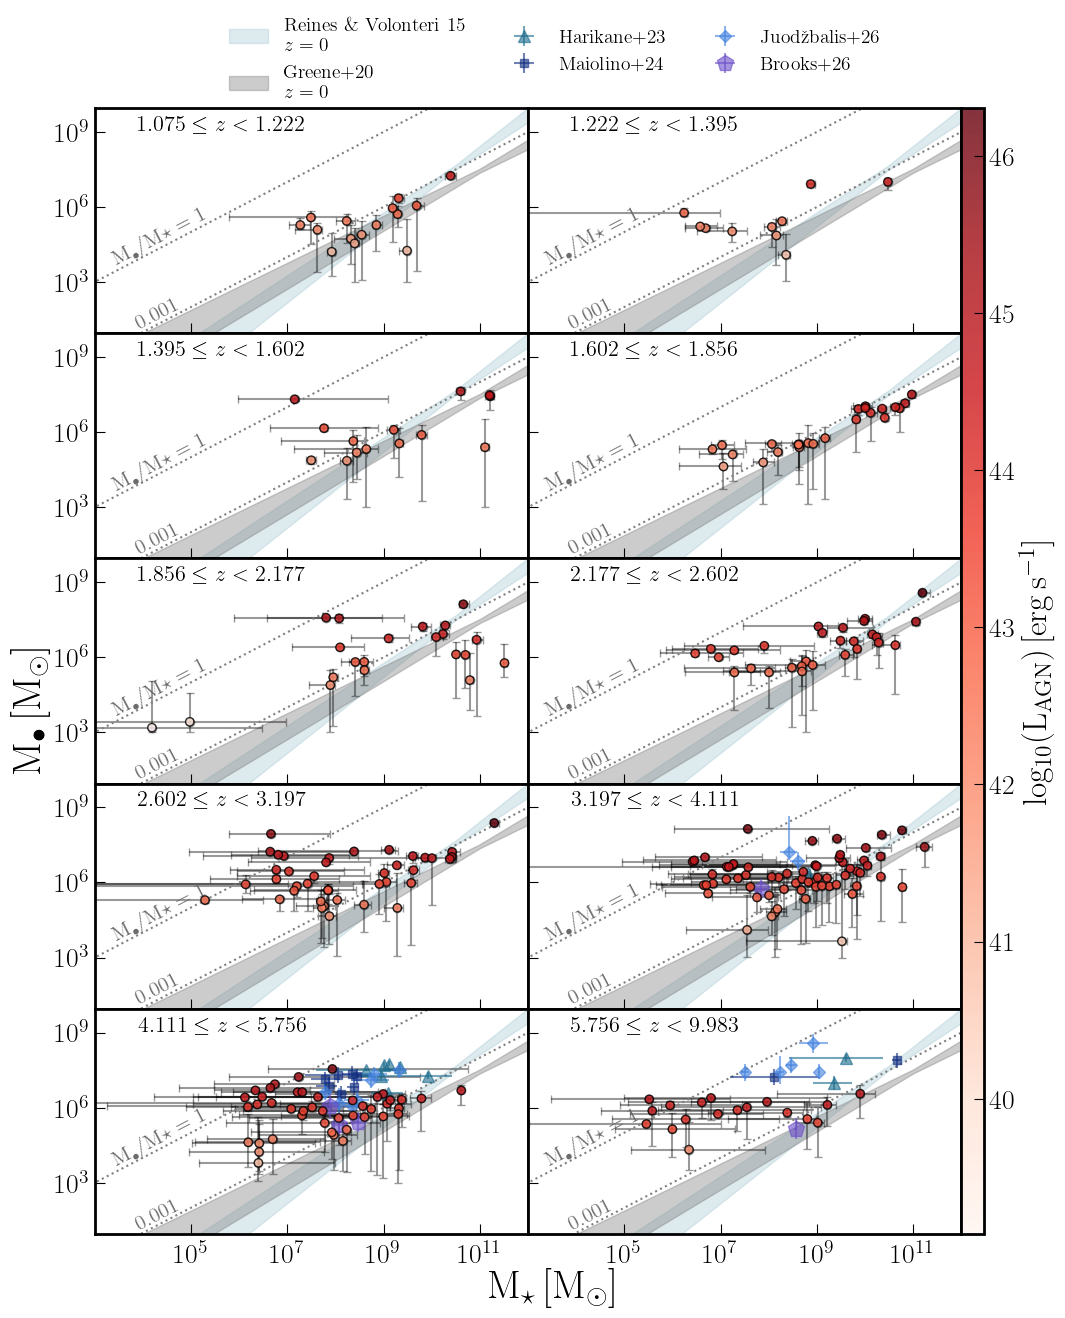

In [206]:
fig, ax = plt.subplots(5,2, figsize = (10,12), sharex=True, sharey=True, layout='constrained')
fig.get_layout_engine().set(h_pad=0, w_pad=0.0, hspace=0, wspace=0)

ax = ax.flatten()

ztot_zidx = (prospect_robust["zQ50"] >= zbins[0]) & (prospect_robust["zQ50"] < zbins[-1])

for i in range(len(zmids)):
    zidx = (prospect_sample["zQ50"] >= zbins[i]) & (prospect_sample["zQ50"] < zbins[i+1])

    ax[i].errorbar(
        prospect_sample["StellarMassQ50"][zidx],
        SMBH_results_sample["m03_SMBHQ50"][zidx],
        xerr = [prospect_sample["StellarMass_lo"][zidx], prospect_sample["StellarMass_hi"][zidx]],
        yerr = [SMBH_results_sample["m03_SMBH_lo"][zidx], SMBH_results_sample["m03_SMBH_hi"][zidx]],
        fmt = "o",
        markerfacecolor = "grey",
        markeredgecolor = "black",
        ecolor = "black",
        capsize = 3,
        alpha = 0.4
    )
    sc_ = ax[i].scatter(
        prospect_sample["StellarMassQ50"][zidx],
        SMBH_results_sample["m03_SMBHQ50"][zidx],
        c = np.log10(prospect_sample["AGNlumQ50"][zidx]),
        edgecolor = "black",
        vmin = np.nanmin(np.log10(prospect_sample["AGNlumQ50"][ztot_zidx])),
        vmax = np.nanmax(np.log10(prospect_sample["AGNlumQ50"][ztot_zidx])),
        zorder = 100, 
        cmap='Reds',
        alpha = 0.8
    )

    ax[i].axhline(1, ls = ":", color = "grey")
    ax[i].plot(
        10**np.linspace(0,15,100),
        10**np.linspace(0,15,100),
        ls = ":",
        color = "grey"
    )
    ax[i].plot(
        10**np.linspace(0,15,100),
        1e-3 * 10**np.linspace(0,15,100),
        ls = ":",
        color = "grey"
    )

    ax[i].text(
        0.1,
        0.9,
        rf"${zbins[i]:.3f} \leq z < {zbins[i+1]:.3f}$",
        transform=ax[i].transAxes,
        fontsize = 16
    )

    ax[i].set_xscale('log')
    ax[i].set_yscale('log')

    ax[i].set_xlim([1e3, 1e12])
    ax[i].set_ylim([9e0, 9e9])

    ax[i].set_xticks([1e5, 1e7, 1e9, 1e11])

cbar = fig.colorbar(sc_, ax = ax, label=r'$\mathrm{log_{10}(L_{AGN}) \, [erg \, s^{-1}]}$', pad = 0.0, aspect = 50)

fig.supxlabel(r"$\mathrm{M_{\star} \, [M_{\odot}]}$")
fig.supylabel(r"$\mathrm{M_{\bullet} \, [M_{\odot}]}$", x = -0.045)

# --- NOW the layout is final, so draw and compute angles ---
fig.canvas.draw()

for i in range(len(zmids)):
    x0 = 3e3
    y0 = x0 
    angle = slope_angle(ax[i], x0, y0, slope=1.0)
    ax[i].text(
        x0, y0,
        r"$\mathrm{M_{\bullet}/M\star} =  1$",
        rotation=angle,
        rotation_mode='anchor',
        ha='left', va='bottom',
        fontsize=15,
        color = "dimgrey"
    )

    x0 = 9e3
    y0 = x0 * 1e-3
    angle = slope_angle(ax[i], x0, y0, slope=1.0)
    ax[i].text(
        x0, y0,
        # r"$\mathrm{M_{\bullet}/M_{\star}}$",
        r"0.001",
        rotation=angle,
        rotation_mode='anchor',
        ha='left', va='bottom',
        fontsize=15,
        color = "dimgrey"
    )

for i in range(len(zmids)):
    ax[i].fill_between(
        10**greene20["mstar"],
        10**greene20["smbh_lo"],
        10**greene20["smbh_hi"],
        color = greene20_col,
        alpha = 0.4,
        label = "Reines \\& Volonteri 15 \n $z=0$"
    )
    ax[i].fill_between(
        10**reinesvolonteri15["mstar"],
        10**reinesvolonteri15["smbh_lo"],
        10**reinesvolonteri15["smbh_hi"],
        color = rv15_col,
        alpha = 0.4,
        label = "Greene+20 \n $z=0$"
    )

    zidx = (harikane23["z"] >= zbins[i]) & (harikane23["z"] < zbins[i+1])
    if(sum(zidx) > 0):
        ax[i].errorbar(
            10**harikane23["logMstar"][zidx],
            harikane23["MBH"][zidx],
            xerr = [
                10**(harikane23["logMstar"][zidx]) - 10**(harikane23["logMstar"][zidx] - harikane23["logMstar_lo"][zidx]),
                10**(harikane23["logMstar"][zidx] + harikane23["logMstar_hi"][zidx]) - 10**(harikane23["logMstar"][zidx])
            ],
            yerr = [
                harikane23["MBH_lo"][zidx],
                harikane23["MBH_hi"][zidx]
            ],
            marker = "^",
            markersize = 8,
            alpha = 0.6,
            color = harikane23_col,
            ls = "",
            label = "Harikane+23"
        )

    zidx = (maiolino24["z"] >= zbins[i]) & (maiolino24["z"] < zbins[i+1])
    if(sum(zidx) > 0):
        ax[i].errorbar(
            10**maiolino24["lg_Mstar"][zidx],
            10**maiolino24["lg_MBH"][zidx],
            xerr = [
                10**(maiolino24["lg_Mstar"][zidx]) - 10**(maiolino24["lg_Mstar"][zidx] - maiolino24["lg_Mstar_err_lower"][zidx]),
                10**(maiolino24["lg_Mstar"][zidx] + maiolino24["lg_Mstar_err_upper"][zidx]) - 10**(maiolino24["lg_Mstar"][zidx]),
            ],
            yerr = [
                10**(maiolino24["lg_MBH"][zidx]) - 10**(maiolino24["lg_MBH"][zidx] - maiolino24["lg_MBH_err_lower"][zidx]),
                10**(maiolino24["lg_MBH"][zidx] + maiolino24["lg_MBH_err_upper"][zidx]) - 10**(maiolino24["lg_MBH"][zidx]),
            ],
            marker = "s",
            color = maiolino24_col,
            alpha = 0.6,
            ls = "",
            label = "Maiolino+24"
        )

    zidx = (juodzbalis26["z"] >= zbins[i]) & (juodzbalis26["z"] < zbins[i+1])
    if(sum(zidx) > 0):
        ax[i].errorbar(
            10**juodzbalis26["log_Mstar_FPHO"][zidx],
            10**juodzbalis26["log_MBH"][zidx],
            xerr = [
                10**(juodzbalis26["log_Mstar_FPHO"][zidx]) - 10**(juodzbalis26["log_Mstar_FPHO"][zidx] - juodzbalis26["log_Mstar_FPHO_lo"][zidx]),
                10**(juodzbalis26["log_Mstar_FPHO"][zidx] + juodzbalis26["log_Mstar_FPHO_hi"][zidx]) - 10**(juodzbalis26["log_Mstar_FPHO"][zidx])
            ],
            yerr = [
                10**(juodzbalis26["log_MBH"][zidx]) - 10**(juodzbalis26["log_MBH"][zidx] - juodzbalis26["log_MBH_lo"][zidx]),
                10**(juodzbalis26["log_MBH"][zidx] + juodzbalis26["log_MBH_hi"][zidx]) - 10**(juodzbalis26["log_MBH"][zidx])
            ],
            marker = "D",
            alpha = 0.6,
            color = juodzbalis26_col,
            ls = "",
            label = "Juodžbalis+26"
        )

    zidx = (brooks26["z"] >= zbins[i]) & (brooks26["z"] < zbins[i+1])
    if(sum(zidx) > 0):
        ax[i].errorbar(
            10**brooks26["logMstar"][zidx],
            10**brooks26["logMBH"][zidx],
            xerr = [
                10**(brooks26["logMstar"][zidx]) - 10**(brooks26["logMstar"][zidx] - brooks26["logMstar_lo"][zidx]),
                10**(brooks26["logMstar"][zidx] + brooks26["logMstar_hi"][zidx]) - 10**(brooks26["logMstar"][zidx])
            ],
            yerr = [
                10**(brooks26["logMBH"][zidx]) - 10**(brooks26["logMBH"][zidx] - brooks26["logMBH_lo"][zidx]),
                10**(brooks26["logMBH"][zidx] + brooks26["logMBH_hi"][zidx]) - 10**(brooks26["logMBH"][zidx])
            ],
            marker = "p",
            markersize = 12,
            alpha = 0.6,
            color = brooks26_col,
            ls = "",
            label = "Brooks+26"
        )

handles, labels = ax[9].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.09),  # above the figure
    ncol = 3,
    # ncol=len(labels),            # optional: put all entries on one row
    fontsize=14,
    fancybox=False,
    frameon=False
)

fig.savefig(
    "/Users/jordan/Documents/Epochs/plots/mstar-mbh-z_m03.pdf", 
    dpi = 240,
    bbox_inches="tight"
)

## Mstar MBH, M0=2,4

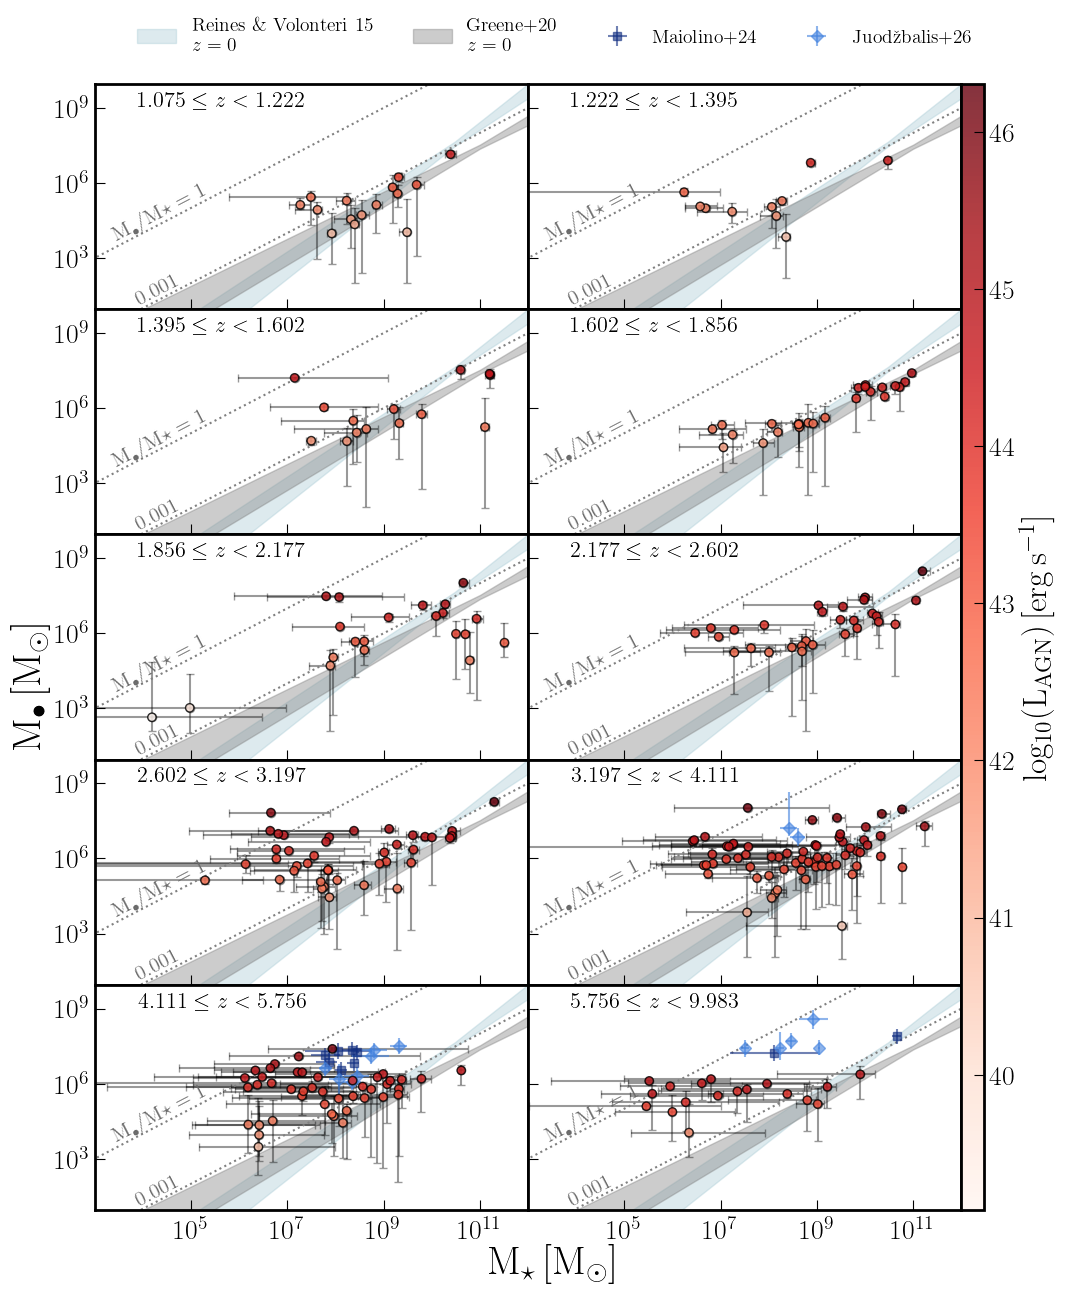

In [61]:
fig, ax = plt.subplots(5,2, figsize = (10,12), sharex=True, sharey=True, layout='constrained')
fig.get_layout_engine().set(h_pad=0, w_pad=0.0, hspace=0, wspace=0)

ax = ax.flatten()

ztot_zidx = (prospect_robust["zQ50"] >= zbins[0]) & (prospect_robust["zQ50"] < zbins[-1])

for i in range(len(zmids)):
    zidx = (prospect_sample["zQ50"] >= zbins[i]) & (prospect_sample["zQ50"] < zbins[i+1])

    ax[i].errorbar(
        prospect_sample["StellarMassQ50"][zidx],
        SMBH_results_sample["m02_SMBHQ50"][zidx],
        xerr = [prospect_sample["StellarMass_lo"][zidx], prospect_sample["StellarMass_hi"][zidx]],
        yerr = [SMBH_results_sample["m02_SMBH_lo"][zidx], SMBH_results_sample["m02_SMBH_hi"][zidx]],
        fmt = "o",
        markerfacecolor = "grey",
        markeredgecolor = "black",
        ecolor = "black",
        capsize = 3,
        alpha = 0.4
    )
    sc_ = ax[i].scatter(
        prospect_sample["StellarMassQ50"][zidx],
        SMBH_results_sample["m02_SMBHQ50"][zidx],
        c = np.log10(prospect_sample["AGNlumQ50"][zidx]),
        edgecolor = "black",
        vmin = np.nanmin(np.log10(prospect_sample["AGNlumQ50"][ztot_zidx])),
        vmax = np.nanmax(np.log10(prospect_sample["AGNlumQ50"][ztot_zidx])),
        zorder = 100, 
        cmap='Reds',
        alpha = 0.8
    )

    ax[i].axhline(1, ls = ":", color = "grey")
    ax[i].plot(
        10**np.linspace(0,15,100),
        10**np.linspace(0,15,100),
        ls = ":",
        color = "grey"
    )
    ax[i].plot(
        10**np.linspace(0,15,100),
        1e-3 * 10**np.linspace(0,15,100),
        ls = ":",
        color = "grey"
    )

    ax[i].text(
        0.1,
        0.9,
        rf"${zbins[i]:.3f} \leq z < {zbins[i+1]:.3f}$",
        transform=ax[i].transAxes,
        fontsize = 16
    )

    ax[i].set_xscale('log')
    ax[i].set_yscale('log')

    ax[i].set_xlim([1e3, 1e12])
    ax[i].set_ylim([9e0, 9e9])

    ax[i].set_xticks([1e5, 1e7, 1e9, 1e11])

cbar = fig.colorbar(sc_, ax = ax, label=r'$\mathrm{log_{10}(L_{AGN}) \, [erg \, s^{-1}]}$', pad = 0.0, aspect = 50)

fig.supxlabel(r"$\mathrm{M_{\star} \, [M_{\odot}]}$")
fig.supylabel(r"$\mathrm{M_{\bullet} \, [M_{\odot}]}$", x = -0.045)

# --- NOW the layout is final, so draw and compute angles ---
fig.canvas.draw()

for i in range(len(zmids)):
    x0 = 3e3
    y0 = x0 
    angle = slope_angle(ax[i], x0, y0, slope=1.0)
    ax[i].text(
        x0, y0,
        r"$\mathrm{M_{\bullet}/M\star} =  1$",
        rotation=angle,
        rotation_mode='anchor',
        ha='left', va='bottom',
        fontsize=15,
        color = "dimgrey"
    )

    x0 = 9e3
    y0 = x0 * 1e-3
    angle = slope_angle(ax[i], x0, y0, slope=1.0)
    ax[i].text(
        x0, y0,
        # r"$\mathrm{M_{\bullet}/M_{\star}}$",
        r"0.001",
        rotation=angle,
        rotation_mode='anchor',
        ha='left', va='bottom',
        fontsize=15,
        color = "dimgrey"
    )

for i in range(len(zmids)):
    ax[i].fill_between(
        10**greene20["mstar"],
        10**greene20["smbh_lo"],
        10**greene20["smbh_hi"],
        color = greene20_col,
        alpha = 0.4,
        label = "Reines \\& Volonteri 15 \n $z=0$"
    )
    ax[i].fill_between(
        10**reinesvolonteri15["mstar"],
        10**reinesvolonteri15["smbh_lo"],
        10**reinesvolonteri15["smbh_hi"],
        color = rv15_col,
        alpha = 0.4,
        label = "Greene+20 \n $z=0$"
    )

    zidx = (maiolino24["z"] >= zbins[i]) & (maiolino24["z"] < zbins[i+1])
    if(sum(zidx) > 0):
        ax[i].errorbar(
            10**maiolino24["lg_Mstar"][zidx],
            10**maiolino24["lg_MBH"][zidx],
            xerr = [
                10**(maiolino24["lg_Mstar"][zidx]) - 10**(maiolino24["lg_Mstar"][zidx] - maiolino24["lg_Mstar_err_lower"][zidx]),
                10**(maiolino24["lg_Mstar"][zidx] + maiolino24["lg_Mstar_err_upper"][zidx]) - 10**(maiolino24["lg_Mstar"][zidx]),
            ],
            yerr = [
                10**(maiolino24["lg_MBH"][zidx]) - 10**(maiolino24["lg_MBH"][zidx] - maiolino24["lg_MBH_err_lower"][zidx]),
                10**(maiolino24["lg_MBH"][zidx] + maiolino24["lg_MBH_err_upper"][zidx]) - 10**(maiolino24["lg_MBH"][zidx]),
            ],
            marker = "s",
            color = maiolino24_col,
            alpha = 0.6,
            ls = "",
            label = "Maiolino+24"
        )

    zidx = (juodzbalis26["z"] >= zbins[i]) & (juodzbalis26["z"] < zbins[i+1])
    if(sum(zidx) > 0):
        ax[i].errorbar(
            10**juodzbalis26["log_Mstar_FPHO"][zidx],
            10**juodzbalis26["log_MBH"][zidx],
            xerr = [
                10**(juodzbalis26["log_Mstar_FPHO"][zidx]) - 10**(juodzbalis26["log_Mstar_FPHO"][zidx] - juodzbalis26["log_Mstar_FPHO_lo"][zidx]),
                10**(juodzbalis26["log_Mstar_FPHO"][zidx] + juodzbalis26["log_Mstar_FPHO_hi"][zidx]) - 10**(juodzbalis26["log_Mstar_FPHO"][zidx])
            ],
            yerr = [
                10**(juodzbalis26["log_MBH"][zidx]) - 10**(juodzbalis26["log_MBH"][zidx] - juodzbalis26["log_MBH_lo"][zidx]),
                10**(juodzbalis26["log_MBH"][zidx] + juodzbalis26["log_MBH_hi"][zidx]) - 10**(juodzbalis26["log_MBH"][zidx])
            ],
            marker = "D",
            alpha = 0.6,
            color = juodzbalis26_col,
            ls = "",
            label = "Juodžbalis+26"
        )

handles, labels = ax[9].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.07),  # above the figure
    ncol=len(labels),            # optional: put all entries on one row
    fontsize=14,
    fancybox=False,
    frameon=False
)

fig.savefig(
    "/Users/jordan/Documents/Epochs/plots/mstar-mbh-z_m02.pdf", 
    dpi = 240,
    bbox_inches="tight"
)

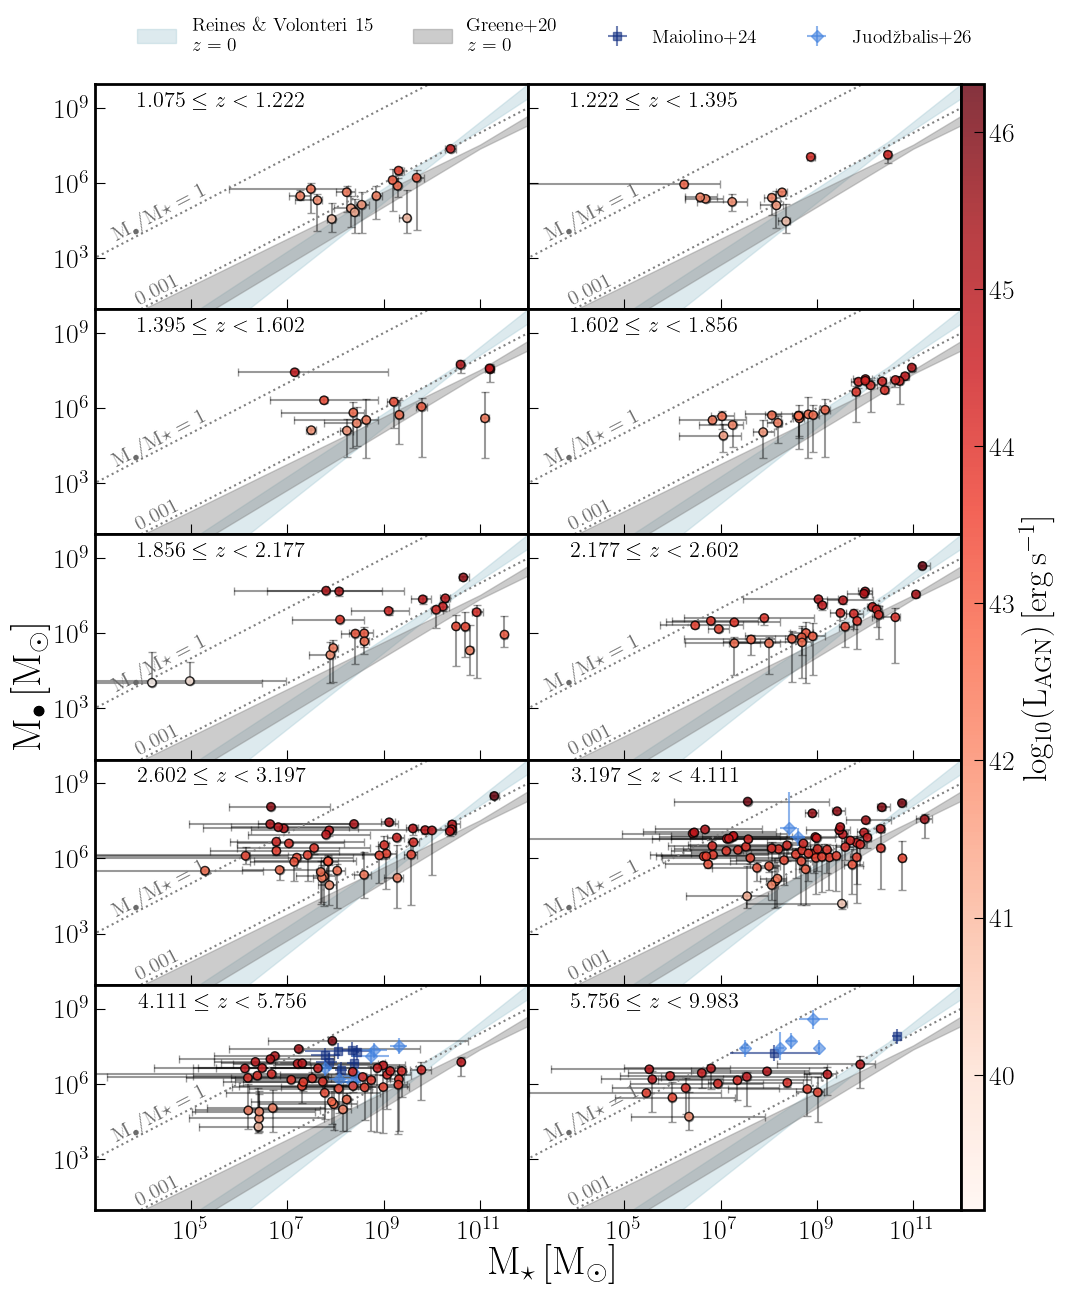

In [ ]:
fig, ax = plt.subplots(5,2, figsize = (10,12), sharex=True, sharey=True, layout='constrained')
fig.get_layout_engine().set(h_pad=0, w_pad=0.0, hspace=0, wspace=0)

ax = ax.flatten()

ztot_zidx = (prospect_robust["zQ50"] >= zbins[0]) & (prospect_robust["zQ50"] < zbins[-1])

for i in range(len(zmids)):
    zidx = (prospect_sample["zQ50"] >= zbins[i]) & (prospect_sample["zQ50"] < zbins[i+1])

    ax[i].errorbar(
        prospect_sample["StellarMassQ50"][zidx],
        SMBH_results_sample["m04_SMBHQ50"][zidx],
        xerr = [prospect_sample["StellarMass_lo"][zidx], prospect_sample["StellarMass_hi"][zidx]],
        yerr = [SMBH_results_sample["m04_SMBH_lo"][zidx], SMBH_results_sample["m04_SMBH_hi"][zidx]],
        fmt = "o",
        markerfacecolor = "grey",
        markeredgecolor = "black",
        ecolor = "black",
        capsize = 3,
        alpha = 0.4
    )
    sc_ = ax[i].scatter(
        prospect_sample["StellarMassQ50"][zidx],
        SMBH_results_sample["m04_SMBHQ50"][zidx],
        c = np.log10(prospect_sample["AGNlumQ50"][zidx]),
        edgecolor = "black",
        vmin = np.nanmin(np.log10(prospect_sample["AGNlumQ50"][ztot_zidx])),
        vmax = np.nanmax(np.log10(prospect_sample["AGNlumQ50"][ztot_zidx])),
        zorder = 100, 
        cmap='Reds',
        alpha = 0.8
    )

    ax[i].axhline(1, ls = ":", color = "grey")
    ax[i].plot(
        10**np.linspace(0,15,100),
        10**np.linspace(0,15,100),
        ls = ":",
        color = "grey"
    )
    ax[i].plot(
        10**np.linspace(0,15,100),
        1e-3 * 10**np.linspace(0,15,100),
        ls = ":",
        color = "grey"
    )

    ax[i].text(
        0.1,
        0.9,
        rf"${zbins[i]:.3f} \leq z < {zbins[i+1]:.3f}$",
        transform=ax[i].transAxes,
        fontsize = 16
    )

    ax[i].set_xscale('log')
    ax[i].set_yscale('log')

    ax[i].set_xlim([1e3, 1e12])
    ax[i].set_ylim([9e0, 9e9])

    ax[i].set_xticks([1e5, 1e7, 1e9, 1e11])

cbar = fig.colorbar(sc_, ax = ax, label=r'$\mathrm{log_{10}(L_{AGN}) \, [erg \, s^{-1}]}$', pad = 0.0, aspect = 50)

fig.supxlabel(r"$\mathrm{M_{\star} \, [M_{\odot}]}$")
fig.supylabel(r"$\mathrm{M_{\bullet} \, [M_{\odot}]}$", x = -0.045)

# --- NOW the layout is final, so draw and compute angles ---
fig.canvas.draw()

for i in range(len(zmids)):
    x0 = 3e3
    y0 = x0 
    angle = slope_angle(ax[i], x0, y0, slope=1.0)
    ax[i].text(
        x0, y0,
        r"$\mathrm{M_{\bullet}/M\star} =  1$",
        rotation=angle,
        rotation_mode='anchor',
        ha='left', va='bottom',
        fontsize=15,
        color = "dimgrey"
    )

    x0 = 9e3
    y0 = x0 * 1e-3
    angle = slope_angle(ax[i], x0, y0, slope=1.0)
    ax[i].text(
        x0, y0,
        # r"$\mathrm{M_{\bullet}/M_{\star}}$",
        r"0.001",
        rotation=angle,
        rotation_mode='anchor',
        ha='left', va='bottom',
        fontsize=15,
        color = "dimgrey"
    )

for i in range(len(zmids)):
    ax[i].fill_between(
        10**greene20["mstar"],
        10**greene20["smbh_lo"],
        10**greene20["smbh_hi"],
        color = greene20_col,
        alpha = 0.4,
        label = "Reines \\& Volonteri 15 \n $z=0$"
    )
    ax[i].fill_between(
        10**reinesvolonteri15["mstar"],
        10**reinesvolonteri15["smbh_lo"],
        10**reinesvolonteri15["smbh_hi"],
        color = rv15_col,
        alpha = 0.4,
        label = "Greene+20 \n $z=0$"
    )

    zidx = (maiolino24["z"] >= zbins[i]) & (maiolino24["z"] < zbins[i+1])
    if(sum(zidx) > 0):
        ax[i].errorbar(
            10**maiolino24["lg_Mstar"][zidx],
            10**maiolino24["lg_MBH"][zidx],
            xerr = [
                10**(maiolino24["lg_Mstar"][zidx]) - 10**(maiolino24["lg_Mstar"][zidx] - maiolino24["lg_Mstar_err_lower"][zidx]),
                10**(maiolino24["lg_Mstar"][zidx] + maiolino24["lg_Mstar_err_upper"][zidx]) - 10**(maiolino24["lg_Mstar"][zidx]),
            ],
            yerr = [
                10**(maiolino24["lg_MBH"][zidx]) - 10**(maiolino24["lg_MBH"][zidx] - maiolino24["lg_MBH_err_lower"][zidx]),
                10**(maiolino24["lg_MBH"][zidx] + maiolino24["lg_MBH_err_upper"][zidx]) - 10**(maiolino24["lg_MBH"][zidx]),
            ],
            marker = "s",
            color = maiolino24_col,
            alpha = 0.6,
            ls = "",
            label = "Maiolino+24"
        )

    zidx = (juodzbalis26["z"] >= zbins[i]) & (juodzbalis26["z"] < zbins[i+1])
    if(sum(zidx) > 0):
        ax[i].errorbar(
            10**juodzbalis26["log_Mstar_FPHO"][zidx],
            10**juodzbalis26["log_MBH"][zidx],
            xerr = [
                10**(juodzbalis26["log_Mstar_FPHO"][zidx]) - 10**(juodzbalis26["log_Mstar_FPHO"][zidx] - juodzbalis26["log_Mstar_FPHO_lo"][zidx]),
                10**(juodzbalis26["log_Mstar_FPHO"][zidx] + juodzbalis26["log_Mstar_FPHO_hi"][zidx]) - 10**(juodzbalis26["log_Mstar_FPHO"][zidx])
            ],
            yerr = [
                10**(juodzbalis26["log_MBH"][zidx]) - 10**(juodzbalis26["log_MBH"][zidx] - juodzbalis26["log_MBH_lo"][zidx]),
                10**(juodzbalis26["log_MBH"][zidx] + juodzbalis26["log_MBH_hi"][zidx]) - 10**(juodzbalis26["log_MBH"][zidx])
            ],
            marker = "D",
            alpha = 0.6,
            color = juodzbalis26_col,
            ls = "",
            label = "Juodžbalis+26"
        )

handles, labels = ax[9].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.07),  # above the figure
    ncol=len(labels),            # optional: put all entries on one row
    fontsize=14,
    fancybox=False,
    frameon=False
)

fig.savefig(
    "/Users/jordan/Documents/Epochs/plots/mstar-mbh-z_m04.pdf", 
    dpi = 240,
    bbox_inches="tight"
)

# Ledd histogram

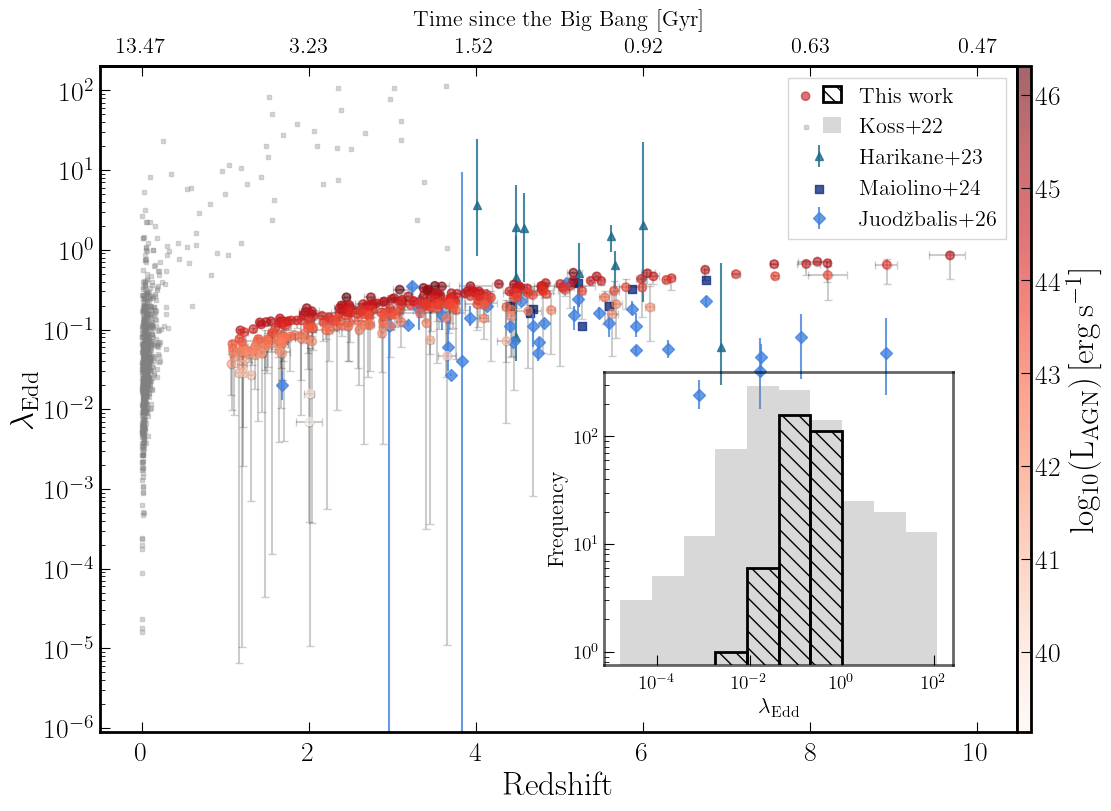

In [162]:
fig, ax = plt.subplots(1,1, figsize = (11,8), layout = 'constrained')

# --- main axes: scatter plots ---
sc_ = ax.scatter(
        prospect_sample["zQ50"],
        SMBH_results_sample["m03_LEddQ50"],
        c = np.log10(prospect_sample["AGNlumQ50"]),
        vmin = np.nanmin(np.log10(prospect_sample["AGNlumQ50"])),
        vmax = np.nanmax(np.log10(prospect_sample["AGNlumQ50"])),
        zorder = 100, 
        cmap='Reds',
        alpha = 0.6
    )
ax.errorbar(
    prospect_sample["zQ50"],
    SMBH_results_sample["m03_LEddQ50"],
    xerr = [prospect_sample["z_lo"], prospect_sample["z_hi"]],
    yerr = [SMBH_results_sample["m03_LEdd_lo"],SMBH_results_sample["m03_LEdd_hi"]],
    marker = "o",
    ls = "",
    capsize = 3,
    markerfacecolor = "none",
    markeredgecolor = "black",
    ecolor = "black",
    alpha = 0.2
)
sc_koss22_ = ax.scatter(
    koss22["z"],
    10**koss22["logEdd"],
    s = 10,
    marker = "s",
    zorder = 100, 
    c = "grey",
    alpha = 0.3
)
sc_harikane23_ = ax.errorbar(
    harikane23["z"],
    harikane23["Ledd"],
    yerr = [
        harikane23["Ledd_lo"],
        harikane23["Ledd_hi"]
    ],
    marker = "^",
    ls = "",
    alpha = 0.8,
    color = harikane23_col,
    label = "Harikane+23"
)
sc_maiolino24_ = ax.scatter(
    maiolino24["z"],
    maiolino24["L_LEdd"],
    marker = "s",
    alpha = 0.8,
    color = maiolino24_col,
    label = "Maiolino+24"
)
sc_juodzbalis26_ = ax.errorbar(
    juodzbalis26["z"],
    juodzbalis26["lambda_Edd"],
    yerr = [
        juodzbalis26["lambda_Edd_lo"],
        juodzbalis26["lambda_Edd_hi"]
    ],
    marker = "D",
    ls = "",
    alpha = 0.8,
    color = juodzbalis26_col,
    label = "Juodžbalis+26"
)
# sc_juodzbalis26_ = ax.scatter(
#     juodzbalis26["z"],
#     juodzbalis26["lambda_Edd"],
#     marker = "D",
#     alpha = 0.8,
#     color = juodzbalis26_col,
#     label = "Juodžbalis+26"
# )

ax.set_xlim([-0.5, zbins[-1]+0.5])
ax.set_yscale("log")
ax.set_ylim([9e-7, 2e2])
ax.set_ylabel(r"$\lambda_{\mathrm{Edd}}$")
ax.set_xlabel(r"Redshift")

# cax = inset_axes(
#     ax,
#     width="2%",
#     height="100%",
#     loc='lower left',
#     bbox_to_anchor=(1.0, 0., 1, 1),
#     bbox_transform=ax.transAxes,
#     borderpad=0,
# )

cbar = fig.colorbar(sc_, ax = ax, label=r'$\mathrm{log_{10}(L_{AGN}) \, [erg \, s^{-1}]}$', pad = 0.0, aspect = 50)
# cbar.ax.yaxis.label.set_size(12)
# cbar.ax.tick_params(labelsize=12)

ax_top = ax.secondary_xaxis('top')
ax_top.set_xticks(ax.get_xticks())
ax_top.set_xticklabels([f"{a:.2f}" for a in cosmo.age(ax.get_xticks()).value], fontsize = 16)
ax_top.set_xlabel("Time since the Big Bang [Gyr]", labelpad=8.0, fontsize = 16)

# --- inset axes: histogram ---
axin1 = ax.inset_axes([0.55, 0.1, 0.38, 0.44])

koss_counts, koss_bin_edges, koss_patches = axin1.hist(
    koss22["logEdd"], 
    color = "grey",
    alpha = 0.3,
    label = "Koss+22"
)
ledd_counts, ledd_bin_edges, ledd_patches = axin1.hist(
    np.log10(SMBH_results_sample["m03_LEddQ50"][SMBH_results_sample["m03_LEddQ50"]>0]), 
    bins = koss_bin_edges,
    facecolor = "none",
    edgecolor = "black", 
    hatch = "\\\\", 
    lw = 2.0,
    label = "This work"
)

axin1.set_yscale("log")
axin1.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: rf"$10^{{{x:g}}}$"))
axin1.patch.set_facecolor("none")
axin1.tick_params(axis='both', which='major', labelsize=14)
axin1.tick_params(axis='both', which='minor', labelsize=14)
axin1.set_xlabel(r"$\lambda_{\mathrm{Edd}}$", fontsize = 16)
axin1.set_ylabel("Frequency", fontsize = 16)
for spine in axin1.spines.values():
    spine.set_alpha(0.6)
    # spine.set_linewidth(1.0)  # optional: thinner too, if it still looks heavy

ax_handles, ax_labels = ax.get_legend_handles_labels()
axin1_handles, axin1_labels = axin1.get_legend_handles_labels()

ax.legend(
    handles=[(sc_, ledd_patches[0]), (sc_koss22_, koss_patches[0]), sc_harikane23_, sc_maiolino24_, sc_juodzbalis26_],
    labels = ["This work", "Koss+22", "Harikane+23", "Maiolino+24", "Juodžbalis+26"],
    handler_map={tuple: HandlerTuple(ndivide=None)},
    fontsize=16,
    loc="best",
    fancybox = False
)

fig.savefig(
    "/Users/jordan/Documents/Epochs/plots/ledd_m03.pdf", 
    dpi = 240,
    bbox_inches="tight"
)

## Ledd M0=2,4

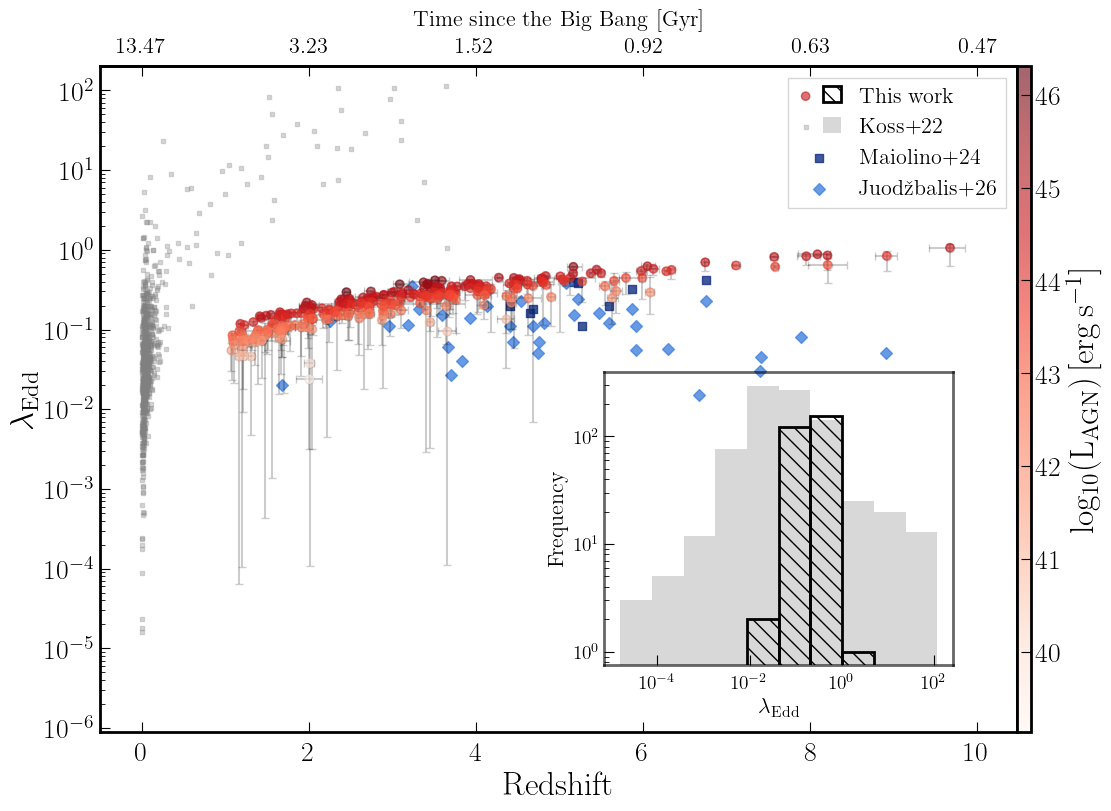

In [64]:
fig, ax = plt.subplots(1,1, figsize = (11,8), layout = 'constrained')

# --- main axes: scatter plots ---
sc_ = ax.scatter(
        prospect_sample["zQ50"],
        SMBH_results_sample["m02_LEddQ50"],
        c = np.log10(prospect_sample["AGNlumQ50"]),
        vmin = np.nanmin(np.log10(prospect_sample["AGNlumQ50"])),
        vmax = np.nanmax(np.log10(prospect_sample["AGNlumQ50"])),
        zorder = 100, 
        cmap='Reds',
        alpha = 0.6
    )
ax.errorbar(
    prospect_sample["zQ50"],
    SMBH_results_sample["m02_LEddQ50"],
    xerr = [prospect_sample["z_lo"], prospect_sample["z_hi"]],
    yerr = [SMBH_results_sample["m02_LEdd_lo"],SMBH_results_sample["m02_LEdd_hi"]],
    marker = "o",
    ls = "",
    capsize = 3,
    markerfacecolor = "none",
    markeredgecolor = "black",
    ecolor = "black",
    alpha = 0.2
)
sc_koss22_ = ax.scatter(
    koss22["z"],
    10**koss22["logEdd"],
    s = 10,
    marker = "s",
    zorder = 100, 
    c = "grey",
    alpha = 0.3
)
sc_maiolino24_ = ax.scatter(
    maiolino24["z"],
    maiolino24["L_LEdd"],
    marker = "s",
    alpha = 0.8,
    color = maiolino24_col,
    label = "Maiolino+24"
)
sc_juodzbalis26_ = ax.scatter(
    juodzbalis26["z"],
    juodzbalis26["lambda_Edd"],
    marker = "D",
    alpha = 0.8,
    color = juodzbalis26_col,
    label = "Juodžbalis+26"
)

ax.set_xlim([-0.5, zbins[-1]+0.5])
ax.set_yscale("log")
ax.set_ylim([9e-7, 2e2])
ax.set_ylabel(r"$\lambda_{\mathrm{Edd}}$")
ax.set_xlabel(r"Redshift")

# cax = inset_axes(
#     ax,
#     width="2%",
#     height="100%",
#     loc='lower left',
#     bbox_to_anchor=(1.0, 0., 1, 1),
#     bbox_transform=ax.transAxes,
#     borderpad=0,
# )

cbar = fig.colorbar(sc_, ax = ax, label=r'$\mathrm{log_{10}(L_{AGN}) \, [erg \, s^{-1}]}$', pad = 0.0, aspect = 50)
# cbar.ax.yaxis.label.set_size(12)
# cbar.ax.tick_params(labelsize=12)

ax_top = ax.secondary_xaxis('top')
ax_top.set_xticks(ax.get_xticks())
ax_top.set_xticklabels([f"{a:.2f}" for a in cosmo.age(ax.get_xticks()).value], fontsize = 16)
ax_top.set_xlabel("Time since the Big Bang [Gyr]", labelpad=8.0, fontsize = 16)

# --- inset axes: histogram ---
axin1 = ax.inset_axes([0.55, 0.1, 0.38, 0.44])

koss_counts, koss_bin_edges, koss_patches = axin1.hist(
    koss22["logEdd"], 
    color = "grey",
    alpha = 0.3,
    label = "Koss+22"
)
ledd_counts, ledd_bin_edges, ledd_patches = axin1.hist(
    np.log10(SMBH_results_sample["m02_LEddQ50"][SMBH_results_sample["m02_LEddQ50"]>0]), 
    bins = koss_bin_edges,
    facecolor = "none",
    edgecolor = "black", 
    hatch = "\\\\", 
    lw = 2.0,
    label = "This work"
)

axin1.set_yscale("log")
axin1.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: rf"$10^{{{x:g}}}$"))
axin1.patch.set_facecolor("none")
axin1.tick_params(axis='both', which='major', labelsize=14)
axin1.tick_params(axis='both', which='minor', labelsize=14)
axin1.set_xlabel(r"$\lambda_{\mathrm{Edd}}$", fontsize = 16)
axin1.set_ylabel("Frequency", fontsize = 16)
for spine in axin1.spines.values():
    spine.set_alpha(0.6)
    # spine.set_linewidth(1.0)  # optional: thinner too, if it still looks heavy

ax_handles, ax_labels = ax.get_legend_handles_labels()
axin1_handles, axin1_labels = axin1.get_legend_handles_labels()

ax.legend(
    handles=[(sc_, ledd_patches[0]), (sc_koss22_, koss_patches[0]), sc_maiolino24_, sc_juodzbalis26_],
    labels = ["This work", "Koss+22", "Maiolino+24", "Juodžbalis+26"],
    handler_map={tuple: HandlerTuple(ndivide=None)},
    fontsize=16,
    loc="best",
    fancybox = False
)

fig.savefig(
    "/Users/jordan/Documents/Epochs/plots/ledd_m02.pdf", 
    dpi = 240,
    bbox_inches="tight"
)

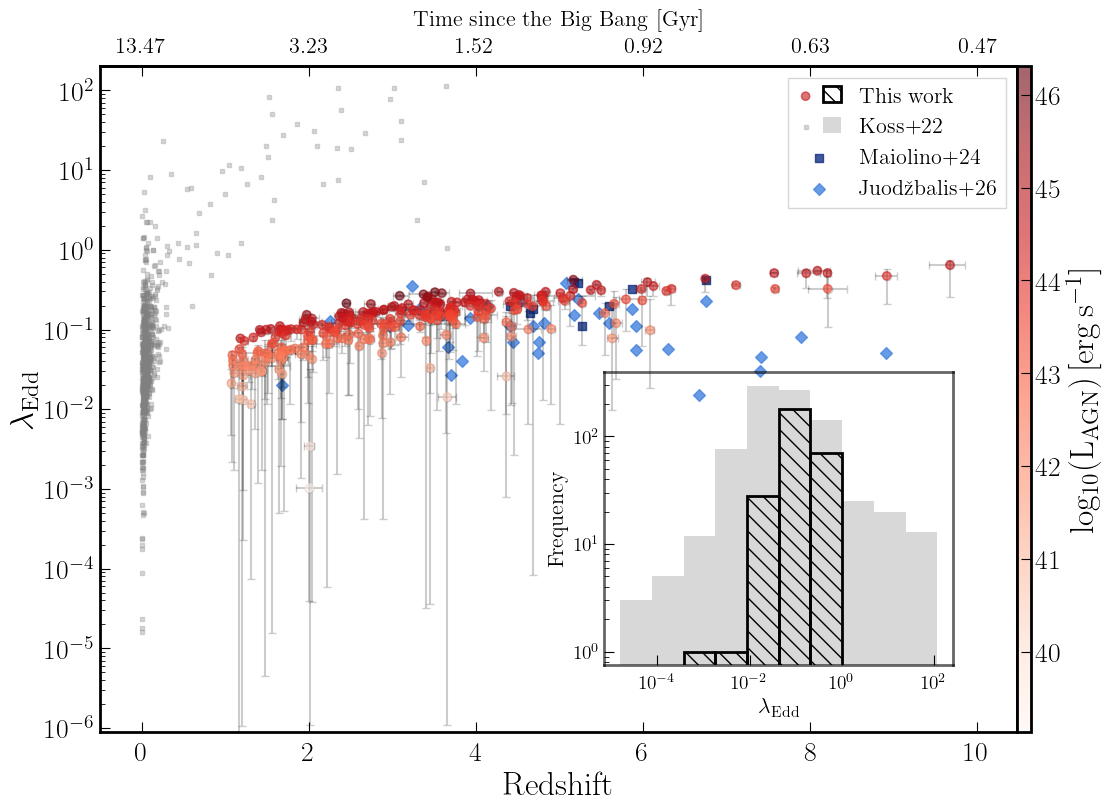

In [65]:
fig, ax = plt.subplots(1,1, figsize = (11,8), layout = 'constrained')

# --- main axes: scatter plots ---
sc_ = ax.scatter(
        prospect_sample["zQ50"],
        SMBH_results_sample["m04_LEddQ50"],
        c = np.log10(prospect_sample["AGNlumQ50"]),
        vmin = np.nanmin(np.log10(prospect_sample["AGNlumQ50"])),
        vmax = np.nanmax(np.log10(prospect_sample["AGNlumQ50"])),
        zorder = 100, 
        cmap='Reds',
        alpha = 0.6
    )
ax.errorbar(
    prospect_sample["zQ50"],
    SMBH_results_sample["m04_LEddQ50"],
    xerr = [prospect_sample["z_lo"], prospect_sample["z_hi"]],
    yerr = [SMBH_results_sample["m04_LEdd_lo"],SMBH_results_sample["m04_LEdd_hi"]],
    marker = "o",
    ls = "",
    capsize = 3,
    markerfacecolor = "none",
    markeredgecolor = "black",
    ecolor = "black",
    alpha = 0.2
)
sc_koss22_ = ax.scatter(
    koss22["z"],
    10**koss22["logEdd"],
    s = 10,
    marker = "s",
    zorder = 100, 
    c = "grey",
    alpha = 0.3
)
sc_maiolino24_ = ax.scatter(
    maiolino24["z"],
    maiolino24["L_LEdd"],
    marker = "s",
    alpha = 0.8,
    color = maiolino24_col,
    label = "Maiolino+24"
)
sc_juodzbalis26_ = ax.scatter(
    juodzbalis26["z"],
    juodzbalis26["lambda_Edd"],
    marker = "D",
    alpha = 0.8,
    color = juodzbalis26_col,
    label = "Juodžbalis+26"
)

ax.set_xlim([-0.5, zbins[-1]+0.5])
ax.set_yscale("log")
ax.set_ylim([9e-7, 2e2])

ax.set_ylabel(r"$\lambda_{\mathrm{Edd}}$")
ax.set_xlabel(r"Redshift")

# cax = inset_axes(
#     ax,
#     width="2%",
#     height="100%",
#     loc='lower left',
#     bbox_to_anchor=(1.0, 0., 1, 1),
#     bbox_transform=ax.transAxes,
#     borderpad=0,
# )

cbar = fig.colorbar(sc_, ax = ax, label=r'$\mathrm{log_{10}(L_{AGN}) \, [erg \, s^{-1}]}$', pad = 0.0, aspect = 50)
# cbar.ax.yaxis.label.set_size(12)
# cbar.ax.tick_params(labelsize=12)

ax_top = ax.secondary_xaxis('top')
ax_top.set_xticks(ax.get_xticks())
ax_top.set_xticklabels([f"{a:.2f}" for a in cosmo.age(ax.get_xticks()).value], fontsize = 16)
ax_top.set_xlabel("Time since the Big Bang [Gyr]", labelpad=8.0, fontsize = 16)

# --- inset axes: histogram ---
axin1 = ax.inset_axes([0.55, 0.1, 0.38, 0.44])

koss_counts, koss_bin_edges, koss_patches = axin1.hist(
    koss22["logEdd"], 
    color = "grey",
    alpha = 0.3,
    label = "Koss+22"
)
ledd_counts, ledd_bin_edges, ledd_patches = axin1.hist(
    np.log10(SMBH_results_sample["m04_LEddQ50"][SMBH_results_sample["m04_LEddQ50"]>0]), 
    bins = koss_bin_edges,
    facecolor = "none",
    edgecolor = "black", 
    hatch = "\\\\", 
    lw = 2.0,
    label = "This work"
)

axin1.set_yscale("log")
axin1.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: rf"$10^{{{x:g}}}$"))
axin1.patch.set_facecolor("none")
axin1.tick_params(axis='both', which='major', labelsize=14)
axin1.tick_params(axis='both', which='minor', labelsize=14)
axin1.set_xlabel(r"$\lambda_{\mathrm{Edd}}$", fontsize = 16)
axin1.set_ylabel("Frequency", fontsize = 16)
for spine in axin1.spines.values():
    spine.set_alpha(0.6)
    # spine.set_linewidth(1.0)  # optional: thinner too, if it still looks heavy

ax_handles, ax_labels = ax.get_legend_handles_labels()
axin1_handles, axin1_labels = axin1.get_legend_handles_labels()

ax.legend(
    handles=[(sc_, ledd_patches[0]), (sc_koss22_, koss_patches[0]), sc_maiolino24_, sc_juodzbalis26_],
    labels = ["This work", "Koss+22", "Maiolino+24", "Juodžbalis+26"],
    handler_map={tuple: HandlerTuple(ndivide=None)},
    fontsize=16,
    loc="best",
    fancybox = False
)

fig.savefig(
    "/Users/jordan/Documents/Epochs/plots/ledd_m04.pdf", 
    dpi = 240,
    bbox_inches="tight"
)

# Compare stuff between different M0

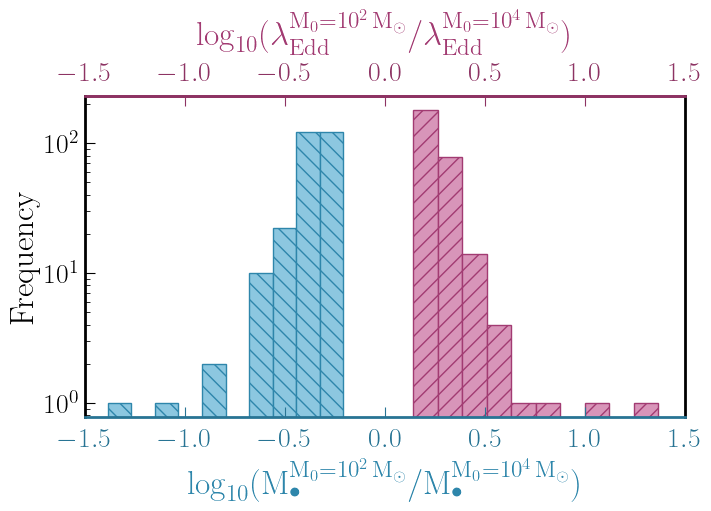

In [ ]:
fig, ax = plt.subplots(1,1, figsize = (7,5), layout = 'constrained')
ax = [ax]

ax[0].hist(
    np.log10(SMBH_results_sample["m02_SMBHQ50"][SMBH_results_sample["m02_SMBHQ50"]>0]/SMBH_results_sample["m04_SMBHQ50"][SMBH_results_sample["m04_SMBHQ50"]>0]),
    hatch = "\\\\",
    edgecolor = "#2E86AB",
    facecolor = lighten_color("#2E86AB", amount=0.5)
)
ax[0].hist(
    np.log10(SMBH_results_sample["m02_LEddQ50"][SMBH_results_sample["m02_LEddQ50"]>0]/SMBH_results_sample["m04_LEddQ50"][SMBH_results_sample["m04_LEddQ50"]>0]),
    hatch = "//",
    edgecolor = "#A23B72",
    facecolor = lighten_color("#A23B72", amount=0.5)
)

ax[0].set_xlim(-1.5,1.5)
# ax[1].set_xlim(-1.5,1.5)

ax[0].set_yscale("log")
# ax[1].set_yscale("log")

# --- Bottom axis (primary) ---
ax[0].set_xlabel(
    r"$\mathrm{ \log_{10}(M_{\bullet}^{M_{0}=10^{2} \, M_{\odot}}/ M_{\bullet}^{M_{0}=10^{4} \, M_{\odot} }) }$",
    color="#2E86AB"
)
ax[0].spines["bottom"].set_color(lighten_color("#2E86AB", 1.1))
ax[0].tick_params(axis="x", which="both", colors=lighten_color("#2E86AB", 1.1))

# --- Top axis (secondary) ---
ax_top = ax[0].secondary_xaxis('top')
ax_top.set_xlabel(
    r"$\mathrm{ \log_{10}(\lambda_{Edd}^{M_{0}=10^{2} \, M_{\odot}}/ \lambda_{Edd}^{M_{0}=10^{4} \, M_{\odot} }) }$",
    color="#A23B72",
    labelpad=12
)
ax[0].spines["top"].set_color(lighten_color("#A23B72", 1.1))
ax_top.spines["top"].set_color(lighten_color("#A23B72", 1.1))
ax_top.tick_params(axis="x", which="both", colors=lighten_color("#A23B72", 1.1))

ax[0].set_ylabel("Frequency")

fig.savefig(
    "/Users/jordan/Documents/Epochs/plots/compare_SMBH_LEdd_M02_M04.pdf", 
    dpi = 240,
    bbox_inches="tight"
)
